# Final Project- ECG Signals

# **Imports**

In [2]:
!pip install wfdb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 1.9 MB/s eta 0:00:00


In [3]:
!pip install tensorflow

In [4]:
!pip install --upgrade tensorflow keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.2/475.2 MB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.2 MB/s eta 0:00:00
  Attempting uninstall: tensorflow
    Found existing installation: tensorflow 2.15.0
    Uninstalling tensorflow-2.15.0:
      Successfully uninstalled tensorflow-2.15.0


In [5]:
!pip install seaborn

In [6]:
!pip install pydot

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import ast
import os

from collections import Counter

from sklearn.preprocessing import FunctionTransformer, MultiLabelBinarizer, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,accuracy_score,\
                             precision_score, recall_score, f1_score,\
                             multilabel_confusion_matrix, classification_report,\
                            hamming_loss, jaccard_score

from sklearn.pipeline import Pipeline
from itertools import combinations, chain
from sklearn.base import BaseEstimator, TransformerMixin

import tensorflow as tf
import keras

import keras.backend as K

from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, BatchNormalization, Activation, Add, Flatten, Dense)
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences

from datetime import datetime

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MultiLabelBinarizer


# **Supporting Functions**

## Loading data:
These code lines are from: https://physionet.org/content/ptb-xl/1.0.3/#files-panel

In [ ]:
def load_raw_data(df, sampling_rate, path):
    if sampling_rate == 100:
        data = [wfdb.rdsamp(path+f) for f in df.filename_lr]
    else:
        data = [wfdb.rdsamp(path+f) for f in df.filename_hr]
    data = np.array([signal for signal, meta in data])
    return data

def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp)) if tmp else ["Not Classified"] # Imputing none classified samples

## Ploting functions:

In [ ]:
def calculate_frequencies(data, labels, replace_zeros_with_nan=False):
    # Flatten the series if it contains lists
    if isinstance(data, pd.Series) and any(isinstance(i, list) for i in data):
        data = data.explode()

    # Replace empty lists or None with 'Not Classified'
    data = data.apply(lambda x: x if x in labels else 'Missing Calssification')

    labels = sorted(set().union(*(list(set(data)), labels))) # Combine and sort all unique labels from all series

    # Calculate the frequencies
    fill_value = pd.NA if replace_zeros_with_nan else 0
    frequency_counts = data.value_counts().reindex(labels, fill_value=fill_value)

    # Calculate total count to handle division by zero
    total_count = frequency_counts.sum(skipna=True)

    # Calculate percentages
    frequency_percentage = (frequency_counts / total_count * 100) if total_count > 0 else pd.Series([fill_value]*len(labels), index=labels)

    # Create the output DataFrame
    frequency_df = pd.DataFrame({
        'Count': frequency_counts,
        'Percentage': frequency_percentage
    })

    return frequency_df

In [ ]:
def plot_grouped_histograms(dataframes, column, title="Frequency Distribution"):
    # Set up the matplotlib figure
    plt.figure(figsize=(10, 6))

    # Number of labels and number of dataframes
    n_labels = len(dataframes[0].index)
    n_dfs = len(dataframes)

    # Width of a bar
    bar_width = 0.8 / n_dfs  # The total width for groups is 0.8 to have some space between groups

    # Create an array with the positions of the leftmost bars
    r = np.arange(n_labels)

    # Iterate over each DataFrame and plot the bars
    for i, df in enumerate(dataframes):
        # Calculate the positions for this DataFrame's bars
        positions = r + i * bar_width

        # Plot the bars
        plt.bar(positions, df[column], width=bar_width, alpha=0.7, label=df.name)

        # Add value labels above each bar
        for pos, val in zip(positions, df[column]):
            label_format = '{:.1f}%'.format(val) if column == 'Percentage' else '{}'.format(int(val))
            plt.text(pos, val, label_format, ha='center', va='bottom', fontsize=8)

        if column == 'Percentage':
            plt.ylim(0,100)

    # General plot settings
    plt.title(title)
    plt.xticks(r + bar_width * (n_dfs - 1) / 2, dataframes[0].index, rotation=45)
    plt.xlabel('Labels')
    plt.ylabel(column)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
def print_dict_results(scores_dict):
  df = pd.DataFrame()

  column_order = ['train_Hamming Loss','test_Hamming Loss',
                  'train_Accuracy- S', 'test_Accuracy- S',
                  'train_Jaccard score- samples', 'test_Jaccard score- samples',
                  'train_Jaccard score- macro', 'test_Jaccard score- macro']

  for model, sub_dict in scores_dict.items():
      model_row = {}
      for dataset, metrics in sub_dict.items():
          for metric, value in metrics.items():
              col_name = f'{dataset}_{metric}'
              model_row[col_name] = float(value)
      df = df.append(pd.Series(model_row, name=model))

  df = df[column_order]
  return df

## Remove data by labels:

In [ ]:
def remove_data_by_labels(X,y, labels):
    remove_ind = []
    new_y = pd.Series([' '.join(map(str, x)) for x in y.values], index = y.index)
    for label in labels:
        ind = new_y[new_y == label].index
        remove_ind.extend(ind)
    keep_ind = ~new_y.index.isin(remove_ind)
    y_filt = new_y.loc[keep_ind]
    X_df = pd.DataFrame({'id': y.index, 'data': [arr for arr in X]} )
    X_df = X_df.set_index('id')
    X_filt = X_df.data.loc[keep_ind]
    X_filt = np.stack(X_filt.values)
    return X_filt, y_filt

## Remove data by patient

In [ ]:
def remove_data_by_patient(X, y, remove_ind):
    keep_ind = ~y.index.isin(remove_ind)
    y_filt = y.loc[keep_ind]
    X_df = pd.DataFrame({'id': y.index, 'data': [arr for arr in X]} )
    X_df = X_df.set_index('id')
    X_filt = X_df.data.loc[keep_ind]
    X_filt = np.stack(X_filt.values)
    return X_filt, y_filt

## Labels interaction

In [ ]:
def label_interaction_matrix(labels_list):
    # Flatten the list to get all label occurrences
    all_labels = list(set(chain.from_iterable(labels_list)))

    # Create an empty DataFrame with all labels as both rows and columns
    interaction_df = pd.DataFrame(0, index=all_labels, columns=all_labels)

    # Fill the DataFrame
    for labels in labels_list:
        # If the list is not empty
        if labels:
            # Increment the count for individual labels
            for label in labels:
                interaction_df.loc[label, label] += 1
            # Increment the count for label interactions
            for (label1, label2) in combinations(labels, 2):
                interaction_df.loc[label1, label2] += 1
                interaction_df.loc[label2, label1] += 1

    return interaction_df

## Filtering Labels Out - without combinations

In [ ]:
def filter_data_by_labels(X,y, lables):

    filter_ind = []
    new_y = pd.Series([' '.join(map(str, x)) for x in y.values], index = y.index)
    for label in labels:
        ind = new_y[new_y == label].index
        filter_ind.extend(ind)
    y_filt = new_y.loc[filter_ind].values
    y_filt = np.where(y_filt == lables[0], 1, 0)
    y_filt = np.column_stack((y_filt, abs(1 - y_filt)))
    X_df = pd.DataFrame({'id': y.index, 'data': [arr for arr in X]} )
    X_df = X_df.set_index('id')
    X_filt = X_df.data.loc[filter_ind]
    X_filt = np.stack(X_filt.values)
    return X_filt, y_filt


## Filtering Labels Out -include combinations

In [ ]:
def filter_labels_and_data(X_data, y_data, labels_to_keep):
    """
    Filters the y_data to only include specified labels and
    corresponding X_data.

    :param X_data: Numpy array with the first dimension matching y_data length
    :param y_data: Pandas Series of lists of labels
    :param labels_to_keep: List of labels to keep
    :return: Tuple of filtered X_data and y_data
    """
    # Filter y_data based on labels_to_keep
    y_filtered = y_data.apply(lambda lst: [label for label in lst if label in labels_to_keep])

    # Find indices where y_filtered lists are not empty
    indices_to_keep = y_filtered.apply(lambda lst: any(label in labels_to_keep for label in lst))

    # Filter X_data based on indices_to_keep
    X_filtered = X_data[indices_to_keep]

    # Filter y_filtered to exclude empty lists
    y_filtered = y_filtered[indices_to_keep]

    return X_filtered, y_filtered

##### Example usage (?)

In [ ]:
# Assuming X_data is a numpy array with the same first dimension as y
y_data = y_train.sample(20)
labels = ['CD','STTC', 'MI']

# Generate X_data
X_data = np.ones([len(y_data),3,3])
for i in range(len(y_data)):
    X_data[i] = X_data[i] * i

X_out, y_out = filter_labels_and_data(X_data, y_data, labels)
print(y_data)
print(X_out)
print(y_out)
print(type(y_out))

NameError: name 'y_train' is not defined

In [ ]:
def single_label_examination(y_true, y_pred):
    f = y_true.sum(axis=1)==1
    y_true_multi_class = np.argmax(y_true, axis=1)[f]
    y_pred_multi_class = np.argmax(y_pred, axis=1)[f]

    cm_singleLabel = confusion_matrix(y_true=y_true_multi_class, y_pred=y_pred_multi_class)
    # Count Validation
    print(f'Input Array Size: {len(y_true_multi_class)}')
    print(f'Confusion Matrix Summary: {cm_singleLabel.sum()}\n')

    # Rows Validation
    frequency = Counter(y_true_multi_class)
    frequency = {k: frequency[k] for k in sorted(frequency)}
    print(f'Actual Frequencies: {frequency}')
    print(f'Confusion Matirx rows sum: {list(cm_singleLabel.sum(axis=1))}')

    # Confusion
    print(f'Confusion Matrix cols sum: {list(cm_singleLabel.sum(axis=0))}')

    plot_confusion_matrix(cm_singleLabel, class_names=mlb.classes_, title='Single-Labeled Confusion Matrix')


## Evaluation metrics:

In [ ]:
def multi_labels_evaluation(y_true, y_pred, class_names, name):
    n= len(class_names)
    dim = n//3 if n%3 == 0 else n//3 +1
    col = n if n%3 !=0 else 3
    fig, axes = plt.subplots(dim, col, figsize=(10, 5))
    for i in range(len(class_names)):
        if dim == 1:
            ax = axes[i % col]
        else:
            ax = axes[i // col, i % col]
        m_cm = multilabel_confusion_matrix(y_true, y_pred)
        disp_cm  = ConfusionMatrixDisplay(confusion_matrix=100*m_cm[i]/np.matrix(m_cm[i]).sum(),
                                    display_labels=['False','True'])
        disp_cm.plot(ax=ax,cmap=plt.cm.Blues,values_format='.1f')
        for im in ax.get_images():
            im.set_clim(vmin=0,vmax=100)
        for text in ax.texts:
            text.set_fontsize(12)
            text.set_fontweight('bold')
        ax.set_title(class_names[i])
    plt.suptitle('Confusion Matrix [%]: ' + name, fontsize=16)
    plt.tight_layout()
    plt.show()
    hamming_loss_val = hamming_loss(y_true, y_pred)
    accuracy_s = accuracy_score(y_true, y_pred)
    jaccard_s = jaccard_score(y_true, y_pred, average='samples')
    jaccard_m = jaccard_score(y_true, y_pred, average='macro')
    print('Hamming loss: {:.2f}'.format(hamming_loss_val))
    print('Accuracy- Strict: {:.2f}'.format(accuracy_s))
    print('Jaccard score- samples: {:.2f}'.format(jaccard_s))
    print('Jaccard score- macro: {:.2f}'.format(jaccard_m))

    print('-------------------------------------------')
    print(classification_report(y_true, y_pred,target_names=class_names))
    return {
          'Hamming Loss': format(hamming_loss_val, '.2f'),
          'Accuracy- S': format(accuracy_s, '.2f'),
          'Jaccard score- samples': format(jaccard_s, '.2f'),
          'Jaccard score- macro': format(jaccard_m, '.2f')

    }

def proba_graph(y_actual, y_pred, class_names, name, bins=50, threashold=.5):
    probs = pd.DataFrame(y_pred, columns=[f'P({x})' for x in class_names], index=y_actual.index)
    y_joined = pd.DataFrame(y_actual).join(probs)

    y_joined['Super-Class'] = y_joined['diagnostic_superclass'].apply(lambda x: ', '.join(sorted(x)))

    dict_probas = {"p": probs[f"P({class_names[0]})"].tolist(), "Super-Class": y_joined['Super-Class']};

    ax = sns.histplot(dict_probas, x="p", bins=bins, hue="Super-Class")
    ax.axvline(x=threashold, color="red")

    ax.set_title("Labels Probability: " + name, fontsize=16)

    ax.set_xlim(0,1.0)



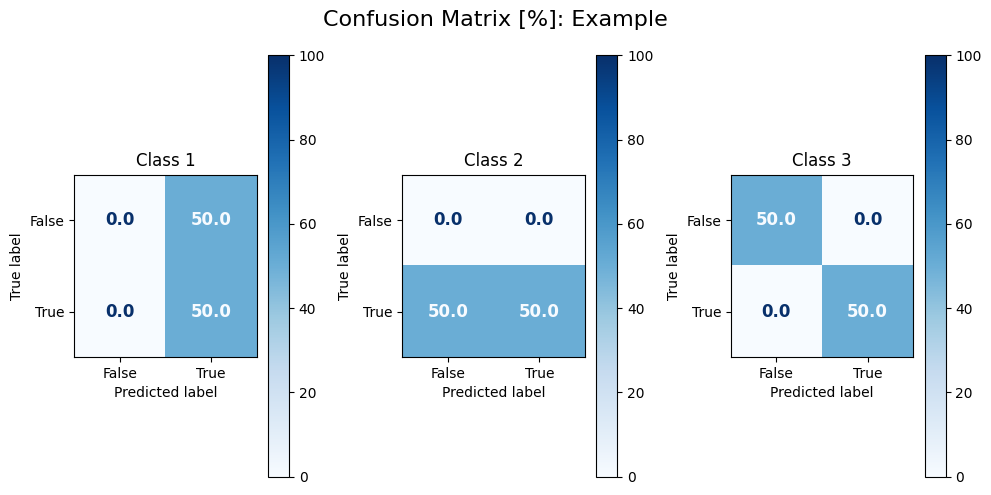

Hamming loss: 0.33
Accuracy- Strict: 0.00
Jaccard score- samples: 0.58
Jaccard score- macro: 0.67
-------------------------------------------
              precision    recall  f1-score   support

     Class 1       0.50      1.00      0.67         1
     Class 2       1.00      0.50      0.67         2
     Class 3       1.00      1.00      1.00         1

   micro avg       0.75      0.75      0.75         4
   macro avg       0.83      0.83      0.78         4
weighted avg       0.88      0.75      0.75         4
 samples avg       0.83      0.75      0.73         4



{'Hamming Loss': '0.33',
 'Accuracy- S': '0.00',
 'Jaccard score- samples': '0.58',
 'Jaccard score- macro': '0.67'}

In [ ]:
#Example Usage:
y_true =  np.array([[0,1,1],[1,1,0]])
y_pred = np.array([[1,1,1],[1,0,0]])
class_names = ['Class 1', 'Class 2', 'Class 3']
multi_labels_evaluation(y_true, y_pred, class_names, "Example")

In [ ]:
#Example Usage:
# proba_graph(y_train_m_encoded, encoded_pred_train, mlb.classes_, "train")

NameError: name 'y_train_m_encoded' is not defined

כרגע זה מה שהפונקציה נותנת. אנסה להפריד אותה לפי לייבלים, כך שייווצר גרף לכל אחד בנפרד (וגם לשילוב ייווצר אחד)

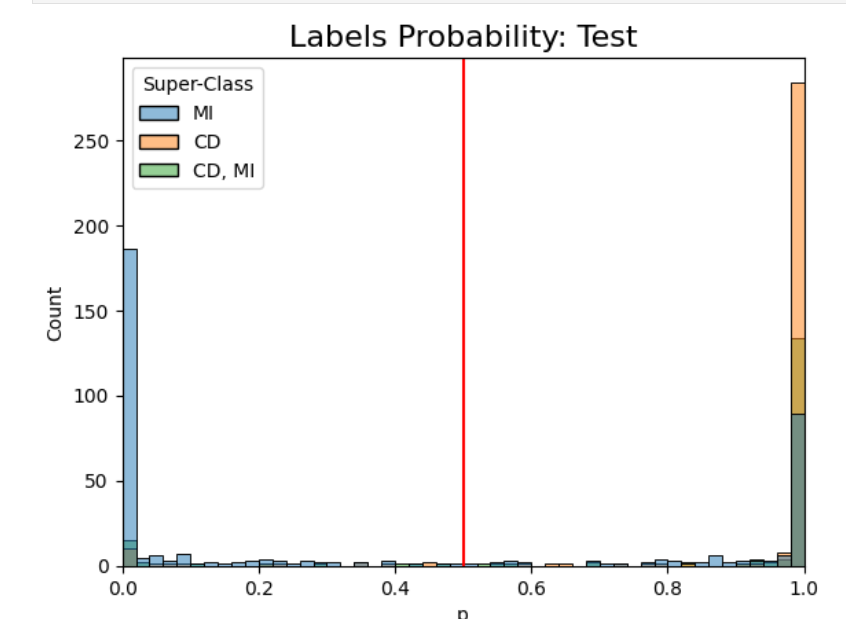

## Multi label confusion matrix:

In [ ]:
def multi_label_confusion_matrix(y_true, y_pred, n_classes):
    """
    Create a 6x6 confusion matrix for multi-label classification.

    :param y_true: True labels (2D array: samples x labels)
    :param y_pred: Predicted labels (2D array: samples x labels)
    :param n_classes: Number of classes
    """
    # Initialize the confusion matrix
    cm = np.zeros((n_classes, n_classes), dtype=int)

    # Populate the confusion matrix
    for i in range(n_classes):
        for j in range(n_classes):
            if i == j:
                # Diagonal: True Positives for class i
                cm[i, j] = np.sum((y_true[:, i] == 1) & (y_pred[:, i] == 1))
            else:
                # Off-diagonal: Count how many times class i was predicted when it was actually class j
                cm[i, j] = np.sum((y_true[:, j] == 1) & (y_pred[:, i] == 1))

    return cm

def plot_confusion_matrix(cm, class_names, title='Multi-Label Confusion Matrix'):
    """
    Plot the confusion matrix.

    :param cm: Confusion matrix
    :param class_names: Names of the classes
    """
    plt.figure()#(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()

# Example usage
# y_true = ... # Your true labels
# y_pred = ... # Your predicted labels
# n_classes = 6
# class_names = ['Class1', 'Class2', 'Class3', 'Class4', 'Class5', 'Class6']
# cm = multi_label_confusion_matrix(y_true, y_pred, n_classes)
# plot_confusion_matrix(cm, class_names)


## CNN model

The CNN is taken from:
Ribeiro, Antônio H., et al. "Automatic diagnosis of the 12-lead ECG using a deep neural network." Nature communications 11.1 (2020): 1760.‏
https://www.nature.com/articles/s41467-020-15432-4#Fig3


In [ ]:

class ResidualUnit(object):
    """Residual unit block (unidimensional).
    Parameters
    ----------
    n_samples_out: int
        Number of output samples.
    n_filters_out: int
        Number of output filters.
    kernel_initializer: str, optional
        Initializer for the weights matrices. See Keras initializers. By default it uses
        'he_normal'.
    dropout_keep_prob: float [0, 1), optional
        Dropout rate used in all Dropout layers. Default is 0.8
    kernel_size: int, optional
        Kernel size for convolutional layers. Default is 17.
    preactivation: bool, optional
        When preactivation is true use full preactivation architecture proposed
        in [1]. Otherwise, use architecture proposed in the original ResNet
        paper [2]. By default it is true.
    postactivation_bn: bool, optional
        Defines if you use batch normalization before or after the activation layer (there
        seems to be some advantages in some cases:
        https://github.com/ducha-aiki/caffenet-benchmark/blob/master/batchnorm.md).
        If true, the batch normalization is used before the activation
        function, otherwise the activation comes first, as it is usually done.
        By default it is false.
    activation_function: string, optional
        Keras activation function to be used. By default 'relu'.
    References
    ----------
    .. [1] K. He, X. Zhang, S. Ren, and J. Sun, "Identity Mappings in Deep Residual Networks,"
           arXiv:1603.05027 [cs], Mar. 2016. https://arxiv.org/pdf/1603.05027.pdf.
    .. [2] K. He, X. Zhang, S. Ren, and J. Sun, "Deep Residual Learning for Image Recognition," in 2016 IEEE Conference
           on Computer Vision and Pattern Recognition (CVPR), 2016, pp. 770-778. https://arxiv.org/pdf/1512.03385.pdf
    """

    def __init__(self, n_samples_out, n_filters_out, kernel_initializer='he_normal',
                 dropout_keep_prob=0.8, kernel_size=17, preactivation=True,
                 postactivation_bn=False, activation_function='relu'):
        self.n_samples_out = n_samples_out
        self.n_filters_out = n_filters_out
        self.kernel_initializer = kernel_initializer
        self.dropout_rate = 1 - dropout_keep_prob
        self.kernel_size = kernel_size
        self.preactivation = preactivation
        self.postactivation_bn = postactivation_bn
        self.activation_function = activation_function

    def _skip_connection(self, y, downsample, n_filters_in):
        """Implement skip connection."""
        # Deal with downsampling
        if downsample > 1:
            y = MaxPooling1D(downsample, strides=downsample, padding='same')(y)
        elif downsample == 1:
            y = y
        else:
            raise ValueError("Number of samples should always decrease.")
        # Deal with n_filters dimension increase
        if n_filters_in != self.n_filters_out:
            # This is one of the two alternatives presented in ResNet paper
            # Other option is to just fill the matrix with zeros.
            y = Conv1D(self.n_filters_out, 1, padding='same',
                       use_bias=False, kernel_initializer=self.kernel_initializer)(y)
        return y

    def _batch_norm_plus_activation(self, x):
        if self.postactivation_bn:
            x = Activation(self.activation_function)(x)
            x = BatchNormalization(center=False, scale=False)(x)
        else:
            x = BatchNormalization()(x)
            x = Activation(self.activation_function)(x)
        return x

    def __call__(self, inputs):
        """Residual unit."""
        x, y = inputs
        n_samples_in = y.shape[1]
        downsample = n_samples_in // self.n_samples_out
        n_filters_in = y.shape[2]
        y = self._skip_connection(y, downsample, n_filters_in)
        # 1st layer
        x = Conv1D(self.n_filters_out, self.kernel_size, padding='same',
                   use_bias=False, kernel_initializer=self.kernel_initializer)(x)
        x = self._batch_norm_plus_activation(x)
        if self.dropout_rate > 0:
            x = Dropout(self.dropout_rate)(x)

        # 2nd layer
        x = Conv1D(self.n_filters_out, self.kernel_size, strides=downsample,
                   padding='same', use_bias=False,
                   kernel_initializer=self.kernel_initializer)(x)
        if self.preactivation:
            x = Add()([x, y])  # Sum skip connection and main connection
            y = x
            x = self._batch_norm_plus_activation(x)
            if self.dropout_rate > 0:
                x = Dropout(self.dropout_rate)(x)
        else:
            x = BatchNormalization()(x)
            x = Add()([x, y])  # Sum skip connection and main connection
            x = Activation(self.activation_function)(x)
            if self.dropout_rate > 0:
                x = Dropout(self.dropout_rate)(x)
            y = x
        return [x, y]


def get_model(n_classes, last_layer='sigmoid', shape=1024, leads=12):
    kernel_size = 16
    kernel_initializer = 'he_normal'
    # signal = Input(shape=(4096, 12), dtype=np.float32, name='signal')
    signal = Input(shape=(shape, leads), dtype=np.float32, name='signal')
    x = signal
    x = Conv1D(64, kernel_size, padding='same', use_bias=False,
               kernel_initializer=kernel_initializer)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    # x, y = ResidualUnit(1024, 128, kernel_size=kernel_size,
    #                     kernel_initializer=kernel_initializer)([x, x])
    # x, y = ResidualUnit(256, 196, kernel_size=kernel_size,
    #                     kernel_initializer=kernel_initializer)([x, y])
    x, y = ResidualUnit(256, 196, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, x])
    x, y = ResidualUnit(64, 256, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, y])
    x, _ = ResidualUnit(16, 320, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, y])
    x = Flatten()(x)
    diagn = Dense(n_classes, activation=last_layer, kernel_initializer=kernel_initializer)(x)
    model = Model(signal, diagn)
    return model


def get_model_4096(n_classes, last_layer='sigmoid', shape=4096, leads=12):
    kernel_size = 16
    kernel_initializer = 'he_normal'
    # signal = Input(shape=(4096, 12), dtype=np.float32, name='signal')
    signal = Input(shape=(shape, leads), dtype=np.float32, name='signal')
    x = signal
    x = Conv1D(64, kernel_size, padding='same', use_bias=False,
               kernel_initializer=kernel_initializer)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x, y = ResidualUnit(1024, 128, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, x])
    x, y = ResidualUnit(256, 196, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, y])
    x, y = ResidualUnit(64, 256, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, y])
    x, _ = ResidualUnit(16, 320, kernel_size=kernel_size,
                        kernel_initializer=kernel_initializer)([x, y])
    x = Flatten()(x)
    diagn = Dense(n_classes, activation=last_layer, kernel_initializer=kernel_initializer)(x)
    model = Model(signal, diagn)
    return model

## Pipeline as function- train

In [ ]:
def train_ecg_model(X_train, y_train, maxlen=1024, learning_rate=0.001, epochs=50, batch_size=64, validation_split=0.1):
    """
    Train an ECG model given training data, and save the trained model and its training history.

    :param X_train: Training data features
    :param y_train: Training data labels
    :param maxlen: Maximum length for padding sequences
    :param learning_rate: Learning rate for the optimizer
    :param epochs: Number of training epochs
    :param batch_size: Batch size for training
    :param validation_split: Fraction of data to use for validation
    :return: Trained model and its history
    """

    # X Padding
    X_train_padded = pad_sequences(X_train, maxlen=maxlen, padding='post', truncating='post')

    # Y Multi Label Encoding
    mlb = MultiLabelBinarizer()
    y_train_m_encoded = mlb.fit_transform(y_train)

    # Build the model
    ecg_model_ml = get_model(len(mlb.classes_))

    # Compile the model
    optimizer = Adam(learning_rate=learning_rate)
    ecg_model_ml.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    # Model Name Creation
    str_date_time = datetime.now().strftime("%Y-%m-%d_%H-%M")
    model_name = f'ECG_mod-CNNml_lab-{len(mlb.classes_)}_TimeStamp_{str_date_time}'

    # Train the model
    history = ecg_model_ml.fit(X_train_padded, y_train_m_encoded, epochs=epochs, batch_size=batch_size, verbose=1, validation_split=validation_split)

    # Save the model and training history
    ecg_model_ml.save(f'{model_name}')
    pd.DataFrame(history.history).to_csv(f'{model_name} History.csv', index=False)

    return model_name, ecg_model_ml, history

# Example usage of the pipeline
# trained_model, training_history = train_ecg_model(X_train, y_train)

## Pipeline as Function - Predict

In [ ]:
def ecg_model_predict(model, X):

    # X Padding
    X_padded = pad_sequences(X, maxlen=maxlen, padding='post', truncating='post')

    # Predict
    pred = model.predict(X_padded)

    return pred

def ecg_model_predict_with_batches(model, X, batch_size = 32):

    # X Padding
    X_padded = pad_sequences(X, maxlen=maxlen, padding='post', truncating='post')

    # Predict
    pred = []
    for i in range(0, len(X_padded), batch_size):
        batch_predictions = model.predict(X_padded[i:i+batch_size])
        pred.append(batch_predictions)

    return np.concatenate(pred, axis=0)

In [ ]:
# path = 'C:/Users/Tal-Shachar/Google Drive/Naya-DS/Final project/Data/'
# path = 'C:/Users/razmm/OneDrive/Documents/GitHub/ECG-project/'
path = ''

# **Data Preparation**

Data can be downloaded from: https://physionet.org/content/ptb-xl/1.0.3/#files-panel

Or download the files using your terminal:

In [ ]:
#wget -r -N -c -np https://physionet.org/files/ptb-xl/1.0.3/

Create the y: Diagnostic Super-Class (classification label)

These code lines are from: https://physionet.org/content/ptb-xl/1.0.3/#files-panel

In [ ]:
# load and convert annotation data to dictionary
Y = pd.read_csv(path+'ptbxl_database.csv', index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))

# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv(path+'scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

# Apply diagnostic superclass
Y['diagnostic_superclass'] = Y.scp_codes.apply(aggregate_diagnostic)

In [ ]:
Y['diagnostic_superclass'].sample(20)

ecg_id
9980               [NORM]
8991                 [MI]
12853              [NORM]
21786            [CD, MI]
10958              [NORM]
8992               [NORM]
16834    [Not Classified]
14271                [CD]
3349                 [CD]
6087               [NORM]
11110       [CD, HYP, MI]
12322     [STTC, HYP, MI]
2711               [NORM]
1222           [CD, STTC]
12303              [STTC]
7736                 [MI]
15579                [MI]
1644               [STTC]
378                  [CD]
21025            [CD, MI]
Name: diagnostic_superclass, dtype: object

Load Raw Signal Data

In [ ]:
sampling_rate=100
test_fold = 10
read_save_data = True

In [ ]:
y_train = Y[(Y.strat_fold != test_fold)].diagnostic_superclass
y_test = Y[Y.strat_fold == test_fold].diagnostic_superclass

if read_save_data == False:
    X = load_raw_data(Y, sampling_rate, path)
    # Train
    X_train = X[np.where(Y.strat_fold != test_fold)]
    # Test
    X_test = X[np.where(Y.strat_fold == test_fold)]

    # Save Data
    np.save('X_test', X_test)
    np.save('X_train', X_train)

else: # Load Data
    X_train = np.load('X_train.npy')
    X_test = np.load('X_test.npy')



##### for Raz

In [ ]:
y_train = Y[(Y.strat_fold != test_fold)].diagnostic_superclass
y_test = Y[Y.strat_fold == test_fold].diagnostic_superclass

if read_save_data == False:
    X = load_raw_data(Y, sampling_rate, path)
    # Train
    X_train = X[np.where(Y.strat_fold != test_fold)]
    # Test
    X_test = X[np.where(Y.strat_fold == test_fold)]

    # Save Data
    np.save(f'X_test_{sampling_rate}Hz', X_test)
    np.save(f'X_train_{sampling_rate}Hz', X_train)

else: # Load Data
    X_train = np.load(f'X_train_{sampling_rate}Hz.npy')
    X_test = np.load(f'X_test_{sampling_rate}Hz.npy')

# **EDA**

Our data compose of main table which contains ECG records of multiple patient. Each row present different ECG recerod and details about the test and the patient.

In [ ]:
data = Y
data.head()

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,diagnostic_superclass
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,[NORM]
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,[NORM]
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,[NORM]
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,[NORM]
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,[NORM]


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 21799 entries, 1 to 21837
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   patient_id                    21799 non-null  float64
 1   age                           21799 non-null  float64
 2   sex                           21799 non-null  int64  
 3   height                        6974 non-null   float64
 4   weight                        9421 non-null   float64
 5   nurse                         20326 non-null  float64
 6   site                          21782 non-null  float64
 7   device                        21799 non-null  object 
 8   recording_date                21799 non-null  object 
 9   report                        21799 non-null  object 
 10  scp_codes                     21799 non-null  object 
 11  heart_axis                    13331 non-null  object 
 12  infarction_stadium1           5612 non-null   object 
 13  i

In our project we will focus on the signals records (X: X_train, X_test) and the classification of the ECG record (Y['diagnostic_superclass']: y_train, y_test)

In [ ]:
X_test.shape

(2198, 1000, 12)

In [ ]:
X_train.shape

(19601, 1000, 12)

#### Looking at one person ECG signal:

X data include records from 12 leads over 10 seconds, as presents in the following figure:

![image.png](attachment:image.png)

In [ ]:
test= pd.DataFrame(X_train[0])
test

,0,1,2,3,4,5,6,7,8,9,10,11
0,-0.119,-0.055,0.064,0.086,-0.091,0.004,-0.069,-0.031,0.000,-0.026,-0.039,-0.079
1,-0.116,-0.051,0.065,0.083,-0.090,0.006,-0.064,-0.036,-0.003,-0.031,-0.034,-0.074
2,-0.120,-0.044,0.076,0.082,-0.098,0.016,-0.058,-0.034,-0.010,-0.028,-0.029,-0.069
3,-0.117,-0.038,0.080,0.077,-0.098,0.021,-0.050,-0.030,-0.015,-0.023,-0.022,-0.064
4,-0.103,-0.031,0.072,0.066,-0.087,0.021,-0.045,-0.027,-0.020,-0.019,-0.018,-0.058
...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.106,0.028,-0.078,-0.067,0.092,-0.025,0.012,-0.008,0.025,0.020,-0.025,0.026
996,0.090,0.021,-0.069,-0.055,0.079,-0.023,-0.014,-0.009,-0.023,-0.027,-0.036,-0.008
997,0.069,0.000,-0.069,-0.034,0.069,-0.035,-0.001,-0.026,0.000,0.024,-0.041,-0.058
998,0.086,0.004,-0.081,-0.044,0.083,-0.038,0.001,-0.001,-0.025,0.242,-0.046,-0.098


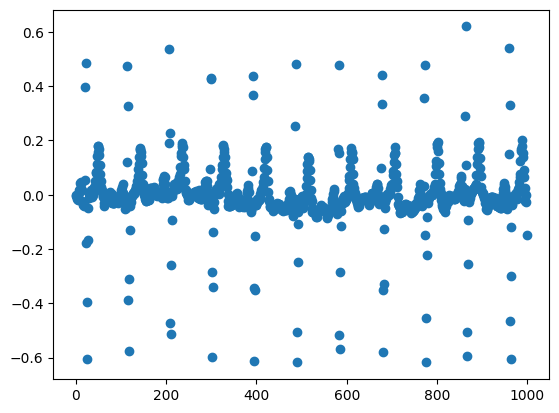

In [ ]:
plt.scatter(test.index.values,test[[8]])

#### Explore y categories:

In [ ]:
y_train.shape, y_test.shape

((19601,), (2198,))

In [ ]:
y_train.value_counts()

[NORM]                 8157
[MI]                   2276
[STTC]                 2158
[CD]                   1524
[CD, MI]               1164
[STTC, HYP]             708
[STTC, MI]              538
[HYP]                   479
[CD, STTC]              433
[Not Classified]        371
[CD, NORM]              362
[STTC, HYP, MI]         320
[CD, HYP]               273
[CD, STTC, MI]          202
[CD, STTC, HYP]         186
[HYP, MI]               166
[CD, STTC, HYP, MI]     140
[CD, HYP, MI]           112
[NORM, STTC]             24
[CD, NORM, STTC]          5
[NORM, HYP]               2
[CD, NORM, HYP, MI]       1
Name: diagnostic_superclass, dtype: int64

In [ ]:
len(y_train.value_counts())

22

In [ ]:
y_test.value_counts()

[NORM]                 912
[MI]                   256
[STTC]                 242
[CD]                   184
[CD, MI]               133
[STTC, HYP]             73
[STTC, MI]              61
[HYP]                   56
[CD, NORM]              45
[STTC, HYP, MI]         41
[Not Classified]        40
[CD, STTC]              38
[CD, HYP]               27
[CD, STTC, HYP]         25
[CD, STTC, MI]          21
[HYP, MI]               17
[CD, STTC, HYP, MI]     16
[CD, HYP, MI]            5
[NORM, STTC]             4
[CD, NORM, HYP]          2
Name: diagnostic_superclass, dtype: int64

In [ ]:
len(y_test.value_counts())

20

There are multiple combinations in diagnostic superclass. Therefore we would like to calculate the main categories (ignore the combinations).

#### Calculate Label Frquencies

In [ ]:
flat_list = [label for sublist in Y['diagnostic_superclass'] for label in sublist]
frequency = Counter(flat_list)
frequency

Counter({'NORM': 9514,
         'MI': 5469,
         'STTC': 5235,
         'CD': 4898,
         'HYP': 2649,
         'Not Classified': 411})

In [ ]:
all_labels = list(set(flat_list))
all_labels

['CD', 'MI', 'HYP', 'STTC', 'NORM', 'Not Classified']

In [ ]:
y_train_freq = calculate_frequencies(y_train, all_labels, replace_zeros_with_nan = True)
y_train_freq

,Count,Percentage
diagnostic_superclass,,
CD,4402,17.369003
HYP,2387,9.418403
MI,4919,19.408933
NORM,8551,33.739741
Not Classified,371,1.463857
STTC,4714,18.600063


In [ ]:
y_test_freq = calculate_frequencies(y_test, all_labels, replace_zeros_with_nan = True)
y_test_freq

,Count,Percentage
diagnostic_superclass,,
CD,496,17.514124
HYP,262,9.251412
MI,550,19.420904
NORM,963,34.004237
Not Classified,40,1.412429
STTC,521,18.396893


#### Comparing y_train and y_test Label Distribtion

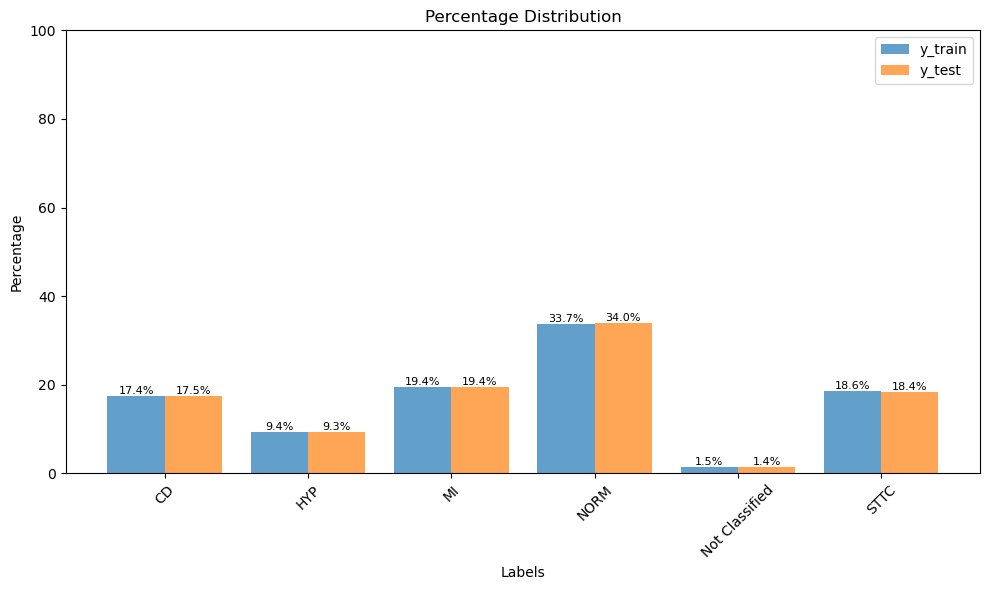

In [ ]:
y_train_freq.name = 'y_train'
y_test_freq.name = 'y_test'


plot_grouped_histograms([y_train_freq, y_test_freq], 'Percentage', "Percentage Distribution")

##### Checking what happens if label is missing

In [ ]:
y_train_no_NORM = y_train.apply(lambda lst: [label for label in lst if label != 'NORM'])
calculate_frequencies(y_train_no_NORM, all_labels, replace_zeros_with_nan = True)

,Count,Percentage
diagnostic_superclass,,
CD,4402.0,17.643287
HYP,2387.0,9.567134
MI,4919.0,19.715431
Missing Calssification,8157.0,32.693387
NORM,NaN,NaN
Not Classified,371.0,1.486974
STTC,4714.0,18.893788


#### Encoding y categories:

In [ ]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train.astype(str))

y_train_one_hot = to_categorical(y_train_encoded, num_classes=len(y_train.value_counts()))

In [ ]:
print("Mapping of categories to encoded labels:")
for category, label in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {label}")

Mapping of categories to encoded labels:
CD: 0
CD HYP STTC: 1
CD STTC: 2
HYP: 3
HYP CD: 4
HYP STTC: 5
HYP STTC CD: 6
MI: 7
MI CD: 8
MI CD STTC: 9
MI HYP: 10
MI HYP CD: 11
MI HYP CD STTC: 12
MI HYP STTC: 13
MI HYP STTC CD: 14
MI NORM HYP CD: 15
MI STTC: 16
MI STTC CD: 17
MI STTC HYP CD: 18
NORM: 19
NORM CD: 20
NORM HYP: 21
NORM STTC: 22
NORM STTC CD: 23
STTC: 24
STTC CD: 25
STTC HYP CD: 26


# **POC**

## **Naive Model**

POC: in order to check if the neural network model is good, lets check first some naive models:

Majority class prediction:

In [ ]:
def naive_predict(x):
    return 19

In [ ]:
y_train_pred_n =[naive_predict(x) for x in range (len(X_train))]

In [ ]:
accuracy_train_naive = accuracy_score(y_true= y_train_encoded, y_pred = y_train_pred_n).round(2)
accuracy_train_naive

0.42

Weightes of 2 major classes prediction:

In [ ]:
y_train_pred_n2 =[7 if x%4 == 0 else 19 for x in range (len(X_train))]

In [ ]:
accuracy_train_naive2 = accuracy_score(y_true= y_train_encoded, y_pred = y_train_pred_n2).round(2)
accuracy_train_naive2

0.34

Weightes of 3 major classes prediction:

In [ ]:
y_train_pred_n3 =[7 if x%3 == 0 else (24 if x % 5 == 0 else 19) for x in range (len(X_train))]

In [ ]:
accuracy_train_naive3 = accuracy_score(y_true= y_train_encoded, y_pred = y_train_pred_n3).round(2)
accuracy_train_naive3

0.28

## **NN Model: 27 labels**

Model from....

#### X Padding

In [ ]:
X_train_padded = pad_sequences(X_train, maxlen=1024, padding='post', truncating='post')
X_test_padded  = pad_sequences(X_test,  maxlen=1024, padding='post', truncating='post')

In [ ]:
ecg_model = get_model(len(y_train.value_counts()))

In [ ]:
ecg_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 signal (InputLayer)         [(None, 1024, 12)]           0         []                            
                                                                                                  
 conv1d_10 (Conv1D)          (None, 1024, 64)             12288     ['signal[0][0]']              
                                                                                                  
 batch_normalization_7 (Bat  (None, 1024, 64)             256       ['conv1d_10[0][0]']           
 chNormalization)                                                                                 
                                                                                                  
 activation_7 (Activation)   (None, 1024, 64)             0         ['batch_normalization_7[0]

                                                                                                  
 conv1d_17 (Conv1D)          (None, 16, 320)              81920     ['max_pooling1d_5[0][0]']     
                                                                                                  
 add_5 (Add)                 (None, 16, 320)              0         ['conv1d_19[0][0]',           
                                                                     'conv1d_17[0][0]']           
                                                                                                  
 batch_normalization_13 (Ba  (None, 16, 320)              1280      ['add_5[0][0]']               
 tchNormalization)                                                                                
                                                                                                  
 activation_13 (Activation)  (None, 16, 320)              0         ['batch_normalization_13[0][0]
          

#### CNN Params

In [ ]:
learning_rate = 0.001
epochs = 10
batch_size=128

In [ ]:
optimizer = Adam(learning_rate=learning_rate)
ecg_model.compile(loss='binary_crossentropy', optimizer= optimizer)

### Fitting:

In [ ]:
ecg_model_history = ecg_model.fit(X_train_padded,y_train_one_hot, epochs = epochs, batch_size=batch_size)

Epoch 1/10
151/151 [==============================] - 1121s 7s/step - loss: 0.0976
Epoch 2/10
151/151 [==============================] - 1053s 7s/step - loss: 0.0949
Epoch 3/10
151/151 [==============================] - 1062s 7s/step - loss: 0.0911
Epoch 4/10
151/151 [==============================] - 1064s 7s/step - loss: 0.0886
Epoch 5/10
151/151 [==============================] - 1063s 7s/step - loss: 0.0858
Epoch 6/10
151/151 [==============================] - 1058s 7s/step - loss: 0.0809
Epoch 7/10
151/151 [==============================] - 1058s 7s/step - loss: 0.0753
Epoch 8/10
151/151 [==============================] - 1055s 7s/step - loss: 0.0671
Epoch 9/10
151/151 [==============================] - 1062s 7s/step - loss: 0.0567
Epoch 10/10
151/151 [==============================] - 1066s 7s/step - loss: 0.0461


C:\Users\Tal-Shachar\anaconda3\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: ecg_model_epoch-10_bs-128_lr-0.001\assets


INFO:tensorflow:Assets written to: ecg_model_epoch-10_bs-128_lr-0.001\assets


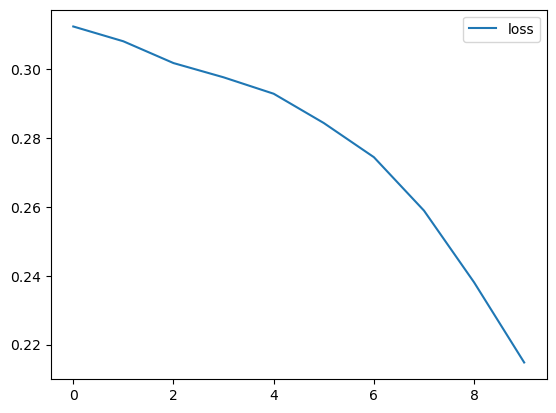

In [ ]:
model_name = f'ecg_model_epoch-{epochs}_bs-{batch_size}_lr-{learning_rate}'
ecg_model.save(f'{model_name}.h5')
ecg_model.save(f'{model_name}')

(pd.DataFrame(ecg_model_history.history)**0.5).plot()
pd.DataFrame(ecg_model_history.history).to_csv(f'{model_name}.csv', index=False)

### Predict:

In [ ]:
batch_size = 32
pred_train = []

for i in range(0, len(X_train_padded), batch_size):
    batch_predictions = ecg_model.predict(X_train_padded[i:i+batch_size])
    pred_train.append(batch_predictions)

pred_train = np.concatenate(pred_train, axis=0)

1/1 [==============================] - 0s 471ms/step


1/1 [==============================] - 1s 513ms/step


1/1 [==============================] - 1s 529ms/step


1/1 [==============================] - 1s 994ms/step


In [ ]:
predicted_labels = np.argmax(pred_train, axis=1)
predicted_labels

array([19, 19, 19, ..., 19, 19, 19], dtype=int64)

In [ ]:
df1= pd.DataFrame(y_train_encoded, columns =['actual'])
df2= pd.DataFrame(predicted_labels, columns =['predicted'])
result_df = pd.concat([df1, df2], axis=1)
result_df.sample(10)

,actual,predicted
18329,19,19
2793,3,3
8247,19,19
13558,5,5
12528,24,24
8201,2,19
13350,5,5
14140,19,19
1669,7,7
1029,24,24


In [ ]:
labels=  list(np.unique(y_train_encoded))

### Evaluation:

In [ ]:
accuracy_train = accuracy_score(y_true= y_train_encoded, y_pred = predicted_labels).round(2)
accuracy_train


0.89

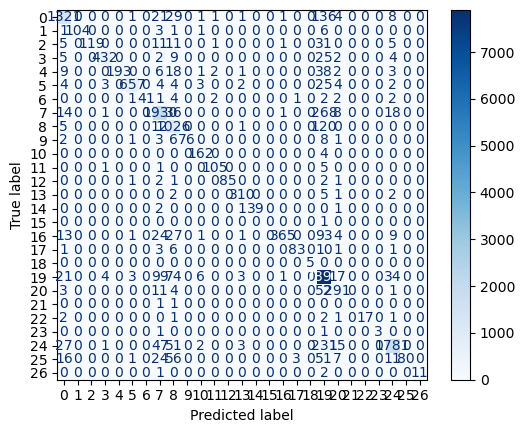

In [ ]:
cm_train = confusion_matrix(y_true= y_train_encoded, y_pred = predicted_labels, labels=labels)
disp_train  = ConfusionMatrixDisplay(confusion_matrix=cm_train,
                                display_labels=labels)
disp_train.plot(cmap=plt.cm.Blues,values_format='g')


### Test results:

In [ ]:
batch_size = 32
pred_test = []

for i in range(0, len(X_test_padded), batch_size):
    batch_predictions = ecg_model.predict(X_test_padded[i:i+batch_size])
    pred_test.append(batch_predictions)

pred_test = np.concatenate(pred_test, axis=0)

1/1 [==============================] - 1s 537ms/step


1/1 [==============================] - 0s 491ms/step


1/1 [==============================] - 1s 550ms/step


1/1 [==============================] - 1s 540ms/step


In [ ]:
y_test_encoded = label_encoder.transform(y_test.astype(str))

ValueError: y contains previously unseen labels: 'N O R M'

In [ ]:
predicted_labels_test = np.argmax(pred_test, axis=1)
predicted_labels_test

In [ ]:
accuracy_test = accuracy_score(y_true= y_test_encoded, y_pred = predicted_labels_test).round(2)
accuracy_test

# **NN model with Multi-label**

### Data Preprocessing:

Y Multi Label Encoding:

In [ ]:
mlb = MultiLabelBinarizer()

In [ ]:
y_train_m_encoded = mlb.fit_transform(y_train)
y_train_m_encoded

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 1, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
y_test_m_encoded = mlb.transform(y_test)
y_test_m_encoded

array([[1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 1, 0, ..., 1, 1, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0]])

### NN model

In [ ]:
ecg_model_ml = get_model(len(mlb.classes_))

In [ ]:
ecg_model_ml.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 signal (InputLayer)         [(None, 1024, 12)]           0         []                            
                                                                                                  
 conv1d_20 (Conv1D)          (None, 1024, 64)             12288     ['signal[0][0]']              
                                                                                                  
 batch_normalization_14 (Ba  (None, 1024, 64)             256       ['conv1d_20[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_14 (Activation)  (None, 1024, 64)             0         ['batch_normalization_14

                                                                                                  
 conv1d_27 (Conv1D)          (None, 16, 320)              81920     ['max_pooling1d_8[0][0]']     
                                                                                                  
 add_8 (Add)                 (None, 16, 320)              0         ['conv1d_29[0][0]',           
                                                                     'conv1d_27[0][0]']           
                                                                                                  
 batch_normalization_20 (Ba  (None, 16, 320)              1280      ['add_8[0][0]']               
 tchNormalization)                                                                                
                                                                                                  
 activation_20 (Activation)  (None, 16, 320)              0         ['batch_normalization_20[0][0]
          

#### CNN Params

In [ ]:
learning_rate = 0.001
epochs = 50
batch_size = 64
validation_split=0.1
thr = 0.5

In [ ]:
optimizer = Adam(learning_rate=learning_rate)
ecg_model_ml.compile(loss='binary_crossentropy', optimizer= optimizer, metrics=['accuracy'])

#### Model Train

In [ ]:
# ecg_model_ml = load_model('ecg_model_epoch-50_bs-128_lr-0.001')

In [ ]:
ecg_model_ml_history = ecg_model_ml.fit(X_train_padded, y_train_m_encoded, epochs=epochs, batch_size=batch_size, verbose=1, validation_split=validation_split)

model_name = f'ecg_multi-label_model_epoch-{epochs}_bs-{batch_size}_lr-{learning_rate}'
ecg_model_ml.save(f'{model_name}.h5')
ecg_model_ml.save(f'{model_name}')

pd.DataFrame((ecg_model_ml_history.history)**0.5).plot()
pd.DataFrame(ecg_model_ml_history.history).to_csv(f'{model_name}.csv', index=False)

Epoch 1/50



159/271 [================>.............] - ETA: 6:17 - loss: 0.5263 - accuracy: 0.3888

In [ ]:
batch_size = 32
pred_train = []

for i in range(0, len(X_train_padded), batch_size):
    batch_predictions = ecg_model_ml.predict(X_train_padded[i:i+batch_size])
    pred_train.append(batch_predictions)

pred_train = np.concatenate(pred_train, axis=0)

1/1 [==============================] - 0s 244ms/step


In [ ]:
encoded_pred_train =(pred_train>thr).astype(int)

In [ ]:
encoded_pred_train

array([[0, 0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0, 0],
       ...,
       [0, 0, 0, 1, 0, 0],
       [1, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0]])

In [ ]:
accuracy_train = accuracy_score(y_true= y_train_m_encoded, y_pred = encoded_pred_train).round(2)
accuracy_train

0.9

In [ ]:
batch_size = 32
pred_test = []

for i in range(0, len(X_test_padded), batch_size):
    batch_predictions = ecg_model_ml.predict(X_test_padded[i:i+batch_size])
    pred_test.append(batch_predictions)

pred_test = np.concatenate(pred_test, axis=0)

1/1 [==============================] - 0s 114ms/step


In [ ]:
pred_test

array([[2.04476310e-04, 3.46564548e-07, 2.19147764e-02, 1.50068505e-02,
        4.70318888e-11, 2.01824624e-02],
       [1.29983388e-02, 3.01246066e-03, 8.73302110e-03, 1.48558974e-01,
        5.93549747e-04, 1.36079150e-04],
       [3.11500003e-06, 1.53925195e-09, 7.08429013e-08, 9.98155057e-01,
        1.92501245e-18, 4.71160922e-04],
       ...,
       [4.21315453e-05, 9.66850102e-01, 4.70930012e-03, 5.02909767e-04,
        1.04177743e-05, 2.24810168e-01],
       [9.99994516e-01, 5.45399787e-04, 8.78373682e-02, 7.09587475e-05,
        1.62922587e-09, 1.19980541e-03],
       [2.31105894e-01, 3.43969305e-06, 9.99802887e-01, 8.41271030e-05,
        1.81426302e-07, 4.10321495e-03]], dtype=float32)

In [ ]:
encoded_pred_test = (pred_test>thr).astype(int)

In [ ]:
accuracy_test = accuracy_score(y_true= y_test_m_encoded, y_pred = encoded_pred_test).round(2)
accuracy_test

0.33

### Evaluation- 1st

In [ ]:
cm = multi_label_confusion_matrix(y_true= y_train_m_encoded, y_pred = encoded_pred_train, n_classes=len(mlb.classes_))

Confusion Matrix rows sum: [7765, 4991, 7780, 8843, 354, 7863]
Confusion Matrix cols sum: [7615, 5004, 7973, 8694, 378, 7932]


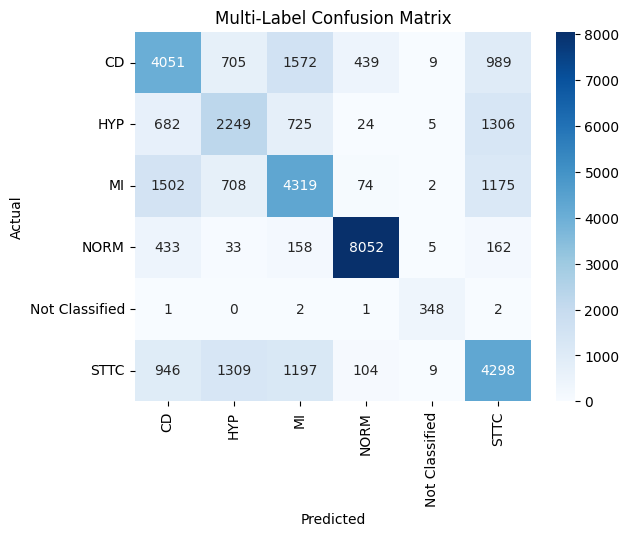

In [ ]:
print(f'Confusion Matrix rows sum: {list(cm.sum(axis=1))}')
print(f'Confusion Matrix cols sum: {list(cm.sum(axis=0))}')

plot_confusion_matrix(cm, class_names=mlb.classes_)

#### Investigation: Examining the Single Labeled

Input Array Size: 1690
Confusion Matrix Summary: 1690

Actual Frequencies: {0: 184, 1: 56, 2: 256, 3: 912, 4: 40, 5: 242}
Confusion Matirx rows sum: [184, 56, 256, 912, 40, 242]
Confusion Matrix cols sum: [616, 53, 145, 740, 15, 121]


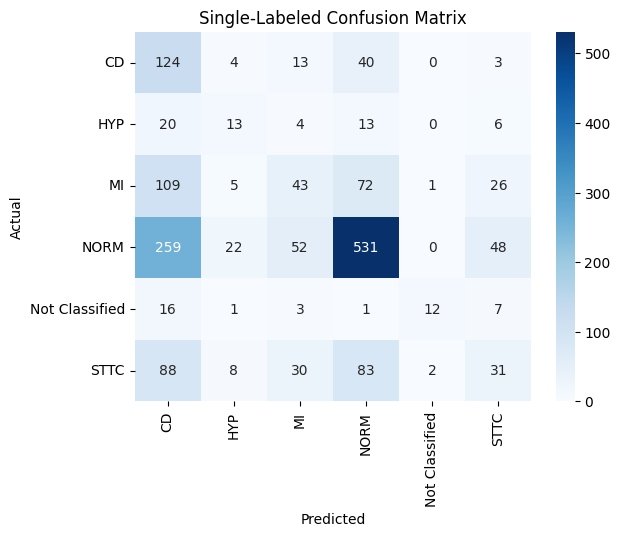

In [ ]:
single_label_examination(y_true=y_test_m_encoded, y_pred=encoded_pred_test)

##### Investigation: Examining the Single Labeled - Step by Step (buillding the function)

In [ ]:
# Single Labeled
single_label = len(y_train_m_encoded[y_train_m_encoded.sum(axis=1)==1])
single_label

14965

In [ ]:
# Multi Labeled
multi_label = len(y_train_m_encoded[y_train_m_encoded.sum(axis=1)>1])
multi_label

4636

In [ ]:
total = len(y_train_m_encoded)
single_label + multi_label == total

True

In [ ]:
f = y_train_m_encoded.sum(axis=1)==1
len(y_train_m_encoded[f])

14965

In [ ]:
y_train_multi_class = np.argmax(y_train_m_encoded, axis=1)[f]
y_train_pred_multi_class = np.argmax(encoded_pred_train, axis=1)[f]
y_train_multi_class, y_train_pred_multi_class

(array([3, 3, 3, ..., 5, 3, 3], dtype=int64),
 array([3, 3, 3, ..., 3, 3, 3], dtype=int64))

Confusion Matirx Summary: 14965, Input Array Size: 14965
Actual Frequecies: {0: 1524, 1: 479, 2: 2276, 3: 8157, 4: 371, 5: 2158}
Confusion Matirx rows sum: [1524, 479, 2276, 8157, 371, 2158]
Confusion Matirx cols sum: [4336, 400, 372, 9025, 240, 592]


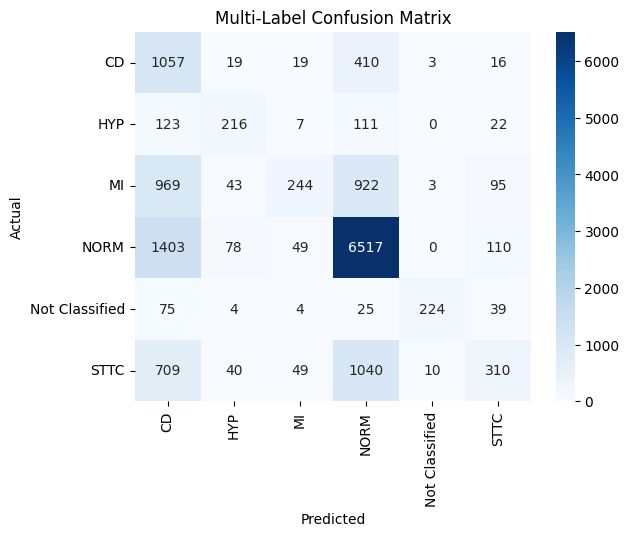

In [ ]:
cm_singleLabel = confusion_matrix(y_true=y_train_multi_class, y_pred=y_train_pred_multi_class)
print(f'Confusion Matirx Summary: {cm_singleLabel.sum()}, Input Array Size: {len(y_train_multi_class)}')
frequency = Counter(y_train_multi_class)
frequency = {k: frequency[k] for k in sorted(frequency)}
print(f'Actual Frequecies: {frequency}')
print(f'Confusion Matirx rows sum: {list(cm_singleLabel.sum(axis=1))}')
print(f'Confusion Matirx cols sum: {list(cm_singleLabel.sum(axis=0))}')

plot_confusion_matrix(cm_singleLabel, class_names=mlb.classes_)

In [ ]:
frequency = Counter(y_train_multi_class)
frequency = {k: frequency[k] for k in sorted(frequency)}
print(frequency)
print(list(cm_singleLabel.sum(axis=1)))

{0: 1524, 1: 479, 2: 2276, 3: 8157, 4: 371, 5: 2158}
[1524, 479, 2276, 8157, 371, 2158]


#### Labels Interaction

In [ ]:
# # Example data
# y = [['NORM'], ['MI'], [], ['STTC'], ['MI', 'CD'], ['NORM'], ['NORM'], [], ['HYP', 'STTC']]

# # Convert empty sublists to a label indicating 'Not Classified'
# y = [sublist if sublist else ['Not Classified'] for sublist in y]

# Call the function
interaction_matrix = label_interaction_matrix(y_train)
interaction_matrix

,MI,Not Classified,CD,NORM,HYP,STTC
MI,4919,0,1619,1,739,1200
Not Classified,0,371,0,0,0,0
CD,1619,0,4402,368,712,966
NORM,1,0,368,8551,3,29
HYP,739,0,712,3,2387,1354
STTC,1200,0,966,29,1354,4714


## Evaluation- 2nd

Load saved data:

In [ ]:
# y_train_m_encoded = np.load('')
# y_test_m_encoded = np.load('')

In [ ]:
# load and convert annotation data to dictionary
Y = pd.read_csv('/content/drive/MyDrive/Naya-DS/Final project/Data/ptbxl_database.csv', index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))

# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv('/content/drive/MyDrive/Naya-DS/Final project/Data/scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

# Apply diagnostic superclass
Y['diagnostic_superclass'] = Y.scp_codes.apply(aggregate_diagnostic)

In [ ]:
y_train = Y[(Y.strat_fold != test_fold)].diagnostic_superclass
y_test = Y[Y.strat_fold == test_fold].diagnostic_superclass

In [ ]:
mlb = MultiLabelBinarizer()
y_train_m_encoded = mlb.fit_transform(y_train)
y_test_m_encoded = mlb.transform(y_test)

In [ ]:
thr= 0.5
y_train_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-10, Multi-Label CNN, 6 Labels/ECG_mod-CNNml_lab-6_epoch-50_bs-64_lr-0.001_y_train_pred.npy')
y_train_pred_encoded = (y_train_pred>thr).astype(int)
y_test_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-10, Multi-Label CNN, 6 Labels/ECG_mod-CNNml_lab-6_epoch-50_bs-64_lr-0.001_y_test_pred.npy')
y_test_pred_encoded = (y_test_pred>thr).astype(int)


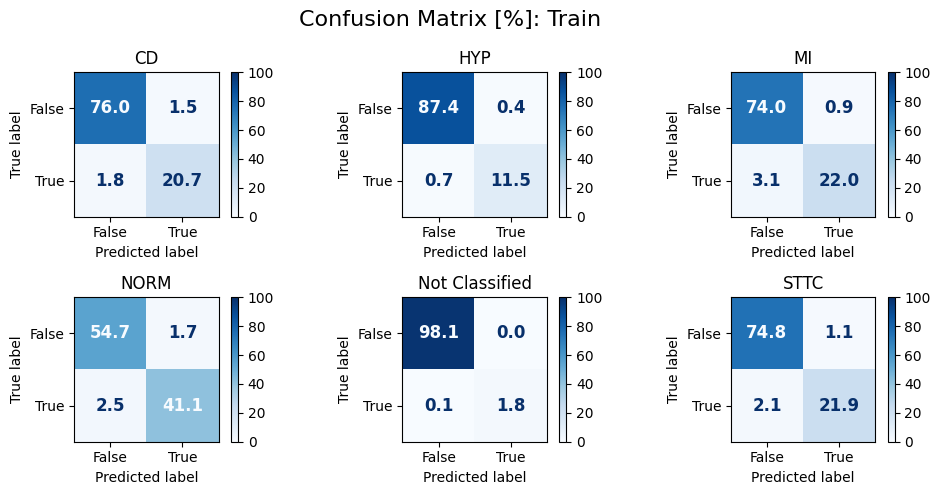

Hamming loss: 0.03
Accuracy- Strict: 0.90
Jaccard score- samples: 0.91
Jaccard score- macro: 0.89
-------------------------------------------
                precision    recall  f1-score   support

            CD       0.93      0.92      0.93      4402
           HYP       0.96      0.94      0.95      2387
            MI       0.96      0.88      0.92      4919
          NORM       0.96      0.94      0.95      8551
Not Classified       0.99      0.94      0.96       371
          STTC       0.95      0.91      0.93      4714

     micro avg       0.95      0.92      0.94     25344
     macro avg       0.96      0.92      0.94     25344
  weighted avg       0.95      0.92      0.94     25344
   samples avg       0.92      0.92      0.92     25344



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
ml_scores_train = multi_labels_evaluation(y_train_m_encoded, y_train_pred_encoded, mlb.classes_, "Train")


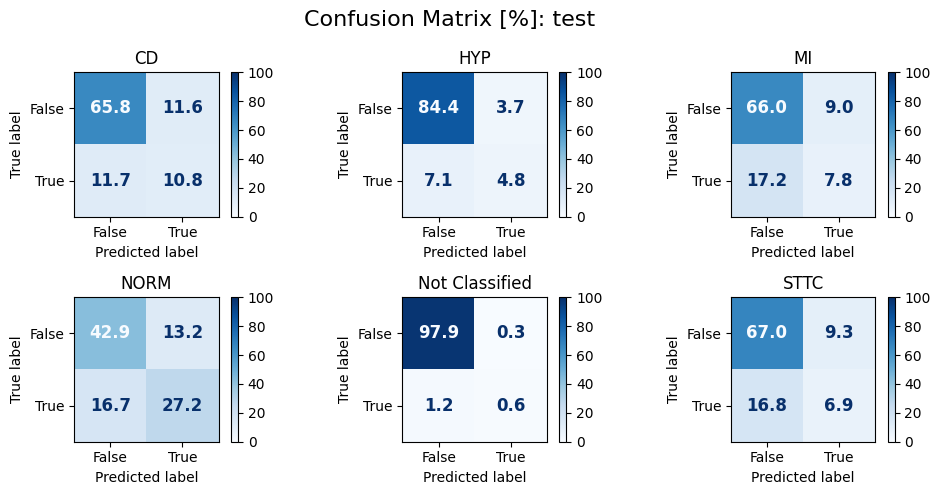

Hamming loss: 0.20
Accuracy- Strict: 0.33
Jaccard score- samples: 0.42
Jaccard score- macro: 0.30
-------------------------------------------
                precision    recall  f1-score   support

            CD       0.48      0.48      0.48       496
           HYP       0.56      0.40      0.47       262
            MI       0.46      0.31      0.37       550
          NORM       0.67      0.62      0.65       963
Not Classified       0.68      0.33      0.44        40
          STTC       0.42      0.29      0.34       521

     micro avg       0.55      0.45      0.50      2832
     macro avg       0.55      0.40      0.46      2832
  weighted avg       0.54      0.45      0.49      2832
   samples avg       0.46      0.46      0.45      2832



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
ml_scores_test = multi_labels_evaluation(y_test_m_encoded, y_test_pred_encoded, mlb.classes_, "test")


In [ ]:
ml_scores_dict = {}
ml_scores_dict['6 labels']= {"train": ml_scores_train, "test": ml_scores_test}

# Multi-label modeling: single sample per patient

## Explore patients duplications:

In [ ]:
y_train_data = Y[(Y.strat_fold != test_fold)]
y_test_data = Y[Y.strat_fold == test_fold]

In [ ]:
counts_train = y_train_data.groupby(['patient_id']).count()['age'].value_counts()
counts_train

1     15082
2      1412
3       309
4        96
5        38
6        15
7         5
8         4
9         3
10        1
Name: age, dtype: int64

In [ ]:
counts_test = y_test_data.groupby(['patient_id']).count()['age'].value_counts()
counts_test

1    1676
2     178
3      41
5       5
4       3
6       1
Name: age, dtype: int64

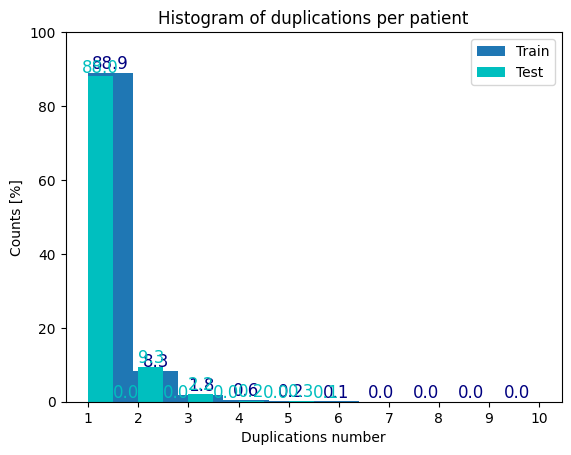

In [ ]:
values, bins, bars =plt.hist(counts_train.index, weights=100*counts_train.values/counts_train.sum(), bins=len(counts_train), label ='Train')
values_2, bins_2, bars_2 =plt.hist(counts_test.index, weights=100*counts_test.values/counts_test.sum(), bins=len(counts_train), label ='Test', color= 'c')

plt.xticks(range(1, len(counts_train) + 1))
plt.bar_label(bars, fmt='%.1f', fontsize=12, color='navy')
plt.bar_label(bars_2, fmt='%.1f', fontsize=12, color='c')
plt.xlabel('Duplications number')
plt.ylabel("Counts [%]")
plt.ylim([0,100])
plt.title('Histogram of duplications per patient')
plt.legend()

In [ ]:
new_counts_train=counts_train[0:3]
new_counts_train[4]= sum(counts_train[3:])
new_counts_train

1    15082
2     1412
3      309
4      162
Name: age, dtype: int64

In [ ]:
new_counts_train.index = [i if i < 4 else '>=4' for i in new_counts_train.index]
new_counts_train

1      15082
2       1412
3        309
>=4      162
Name: age, dtype: int64

([<matplotlib.patches.Wedge at 0x7c25272bb0d0>,
 [Text(-0.563891546042491, 0.20500322997896683, '1'),
  Text(0.5438903028977634, -0.25334430803509117, '2'),
  Text(0.5958826051147095, -0.07017065570241703, '3'),
  Text(0.5997300350528866, -0.01799680681297079, '>=4')],
 [Text(-1.1747740542551897, 0.42709006245618086, '88.9%'),
  Text(1.1331047977036737, -0.5278006417397734, '8.3%'),
  Text(1.2414220939889782, -0.14618886604670214, '1.8%'),
  Text(1.2494375730268472, -0.03749334752702248, '1.0%')])

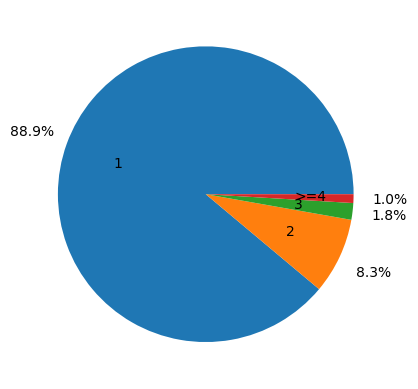

In [ ]:
labels = new_counts_train.index.tolist()
sizes = new_counts_train.values
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct='%1.1f%%',pctdistance=1.25, labeldistance=.6)

## Organize data:

In [ ]:

df_duplicates_train = y_train_data[['patient_id']].loc[y_train_data[['patient_id']].duplicated()].sort_values('patient_id')
ecg_2_remove_train= df_duplicates_train.index
df_duplicates_test = y_test_data[['patient_id']].loc[y_test_data[['patient_id']].duplicated()].sort_values('patient_id')
ecg_2_remove_test= df_duplicates_test.index

X_train_singleID, y_train_singleID = remove_data_by_patient(X_train, y_train, ecg_2_remove_train)
X_test_singleID, y_test_singleID = remove_data_by_patient(X_test, y_test, ecg_2_remove_test)


## Train & Predict

In [ ]:
model_name, ecg_model_ml, history = train_ecg_model(X_train_singleID, y_train_singleID, epochs=2)

Add lines from raz

In [ ]:

y_train_singleID_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-18, Multi-Label CNN, 6 Labels, Single Sample per Patient/ECG_mod-CNNml_lab-6_TimeStamp_2024-01-18_11-46_y_train_singleID_pred.npy')
y_train_singleID_pred_encoded = (y_train_pred>thr).astype(int)
y_test_singleID_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-18, Multi-Label CNN, 6 Labels, Single Sample per Patient/ECG_mod-CNNml_lab-6_TimeStamp_2024-01-18_11-46_y_test_singleID_pred.npy')
y_test_singleID_pred_encoded = (y_test_pred>thr).astype(int)


## Evaluation:

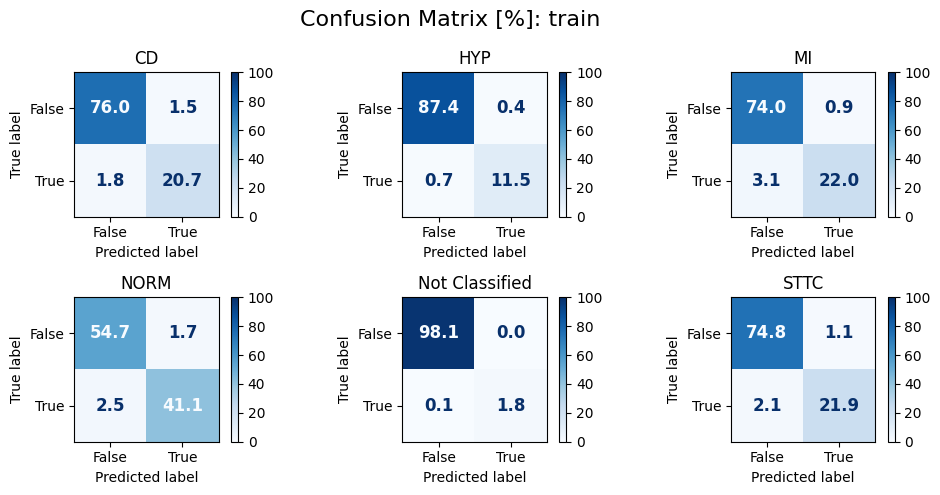

Hamming loss: 0.03
Accuracy- Strict: 0.90
Jaccard score- samples: 0.91
Jaccard score- macro: 0.89
-------------------------------------------
                precision    recall  f1-score   support

            CD       0.93      0.92      0.93      4402
           HYP       0.96      0.94      0.95      2387
            MI       0.96      0.88      0.92      4919
          NORM       0.96      0.94      0.95      8551
Not Classified       0.99      0.94      0.96       371
          STTC       0.95      0.91      0.93      4714

     micro avg       0.95      0.92      0.94     25344
     macro avg       0.96      0.92      0.94     25344
  weighted avg       0.95      0.92      0.94     25344
   samples avg       0.92      0.92      0.92     25344



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
ml_scores_train_singleID = multi_labels_evaluation(y_train_m_encoded, y_train_singleID_pred_encoded, mlb.classes_, "train")


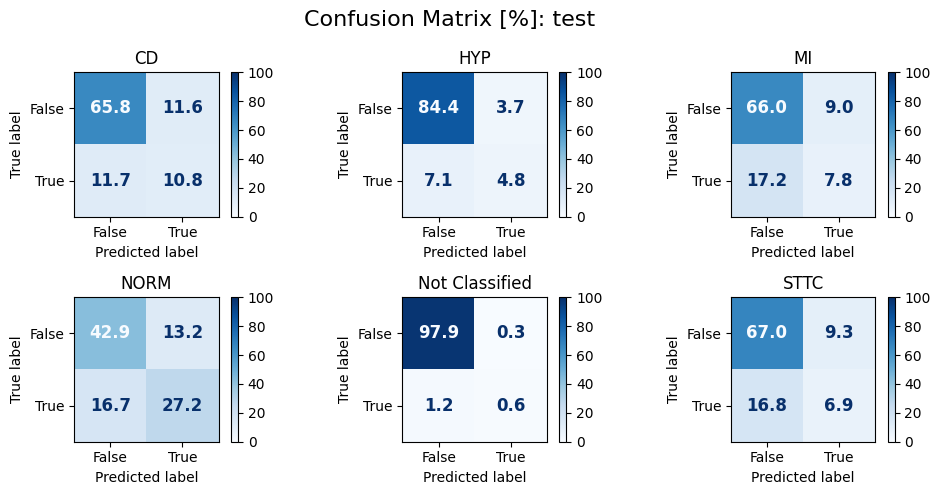

Hamming loss: 0.20
Accuracy- Strict: 0.33
Jaccard score- samples: 0.42
Jaccard score- macro: 0.30
-------------------------------------------
                precision    recall  f1-score   support

            CD       0.48      0.48      0.48       496
           HYP       0.56      0.40      0.47       262
            MI       0.46      0.31      0.37       550
          NORM       0.67      0.62      0.65       963
Not Classified       0.68      0.33      0.44        40
          STTC       0.42      0.29      0.34       521

     micro avg       0.55      0.45      0.50      2832
     macro avg       0.55      0.40      0.46      2832
  weighted avg       0.54      0.45      0.49      2832
   samples avg       0.46      0.46      0.45      2832



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
ml_scores_test_singleID = multi_labels_evaluation(y_test_m_encoded, y_test_singleID_pred_encoded, mlb.classes_, "test")


In [ ]:
ml_scores_dict['6 labels- single ID']= {"train": ml_scores_train_singleID, "test": ml_scores_test_singleID}

In [ ]:
print_dict_results(ml_scores_dict)

<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))
<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))


,train_Hamming Loss,test_Hamming Loss,train_Accuracy- S,test_Accuracy- S,train_Jaccard score- samples,test_Jaccard score- samples,train_Jaccard score- macro,test_Jaccard score- macro
6 labels,0.03,0.2,0.9,0.33,0.91,0.42,0.89,0.3
6 labels- single ID,0.03,0.2,0.9,0.33,0.91,0.42,0.89,0.3


There is no difference in the models scores after change the data to single measurement per patient.

# Model with Less Labels

To check if the problem with our results is related to an imbalance issue, let's explore model scores with balanced data.

### STTC & MI

First examination without connection between the labels, meaning: train for the follwing classification: ['MI'],['STTC']

In [ ]:
filt_X_train, filt_y_train = filter_data_by_labels(X_train_padded, y_train, ['STTC','MI'])
filt_X_test, filt_y_test = filter_data_by_labels(X_test_padded, y_test, ['STTC','MI'])

In [ ]:
ecg_model_IL = get_model(1)

 CNN param

In [ ]:
learning_rate = 0.001
epochs = 30
batch_size = 128
validation_split=0.1

In [ ]:
optimizer = Adam(learning_rate=learning_rate)
ecg_model_IL.compile(loss='binary_crossentropy', optimizer= optimizer, metrics=['accuracy'])

In [ ]:
ecg_model_IL_history = ecg_model_IL.fit(filt_X_train,filt_y_train[:,0], epochs = epochs, batch_size=batch_size,
                                   verbose=1,validation_split=validation_split)

In [ ]:
model_name = f'ecg_STTC_MI_model_epoch-{epochs}_bs-{batch_size}_lr-{learning_rate}'
ecg_model_ml.save(f'{model_name}.h5')
ecg_model_ml.save(f'{model_name}')

pd.DataFrame((ecg_model_IL_history.history)**0.5).plot()
pd.DataFrame(ecg_model_IL_history.history).to_csv(f'{model_name}.csv', index=False)

In [ ]:
y_train_pred = ecg_model_IL.predict(filt_X_train)

In [ ]:
encoded_pred_train =(y_train_pred>thr).astype(int)
accuracy_train = accuracy_score(y_true= filt_y_train[:,0], y_pred = encoded_pred_train).round(2)
accuracy_train

In [ ]:
y_test_pred = ecg_model_IIL.predict(filt_X_test)

In [ ]:
encoded_pred_test =(y_test_pred>thr).astype(int)
accuracy_test = accuracy_score(y_true= filt_y_test[:,0], y_pred = encoded_pred_test).round(2)
accuracy_test

In [ ]:
cm_train = confusion_matrix(y_true= filt_y_train[:,0], y_pred = encoded_pred_train[:,0], labels=[0,1], normalize='true') * 100
disp_train  = ConfusionMatrixDisplay(confusion_matrix=cm_train,
                                display_labels=[0,1])
cm_test = confusion_matrix(y_true= filt_y_test[:,0], y_pred = encoded_pred_test[:,0], labels=[0,1], normalize='true') * 100
disp_test  = ConfusionMatrixDisplay(confusion_matrix=cm_test,
                                display_labels=[0,1])
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
disp_train.plot(ax=axes[0],cmap=plt.cm.Blues,values_format='.1f')
axes[0].set_title('Training Confusion Matrix')
disp_test.plot(ax=axes[1], cmap=plt.cm.Blues,values_format='.1f')
axes[1].set_title('Test Confusion Matrix')
plt.suptitle(model_name, fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
print(f"MI in train: {len(filt_y_train[filt_y_train[:,0]==0])}\nSTTC in train: {len(filt_y_train[filt_y_train[:,0]==1])}")
print(f"MI in test: {len(filt_y_test[filt_y_test[:,0]==0])}\nSTTC in test: {len(filt_y_test[filt_y_test[:,0]==1])}")
print(f"Accuracy train: {accuracy_train}\nAccuracy test: {accuracy_test}")

## 2 Labels (CD, MI), 100Hz

Checking two labels with combinations i.e: ['CD'], ['MI'], ['CD',['MI']

#### Filter and EDA

In [ ]:
labels = ['CD', 'MI']
X_train_filt, y_train_filt = filter_labels_and_data(X_train, y_train, labels)
X_test_filt, y_test_filt = filter_labels_and_data(X_test, y_test, labels)

In [ ]:
y_train_filt_freq = calculate_frequencies(y_train_filt, all_labels, replace_zeros_with_nan = True)
y_train_filt_freq

,Count,Percentage
diagnostic_superclass,,
CD,4402.0,47.226692
HYP,NaN,NaN
MI,4919.0,52.773308
NORM,NaN,NaN
Not Classified,NaN,NaN
STTC,NaN,NaN


In [ ]:
y_test_filt_freq = calculate_frequencies(y_test_filt, all_labels, replace_zeros_with_nan = True)
y_test_filt_freq

,Count,Percentage
diagnostic_superclass,,
CD,496.0,47.418738
HYP,NaN,NaN
MI,550.0,52.581262
NORM,NaN,NaN
Not Classified,NaN,NaN
STTC,NaN,NaN


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


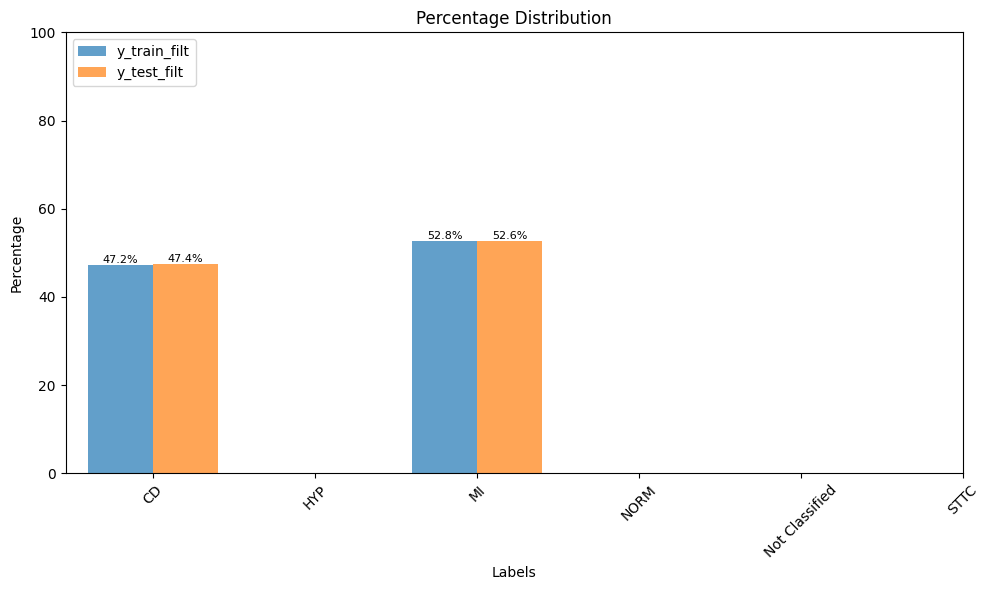

In [ ]:
y_train_filt_freq.name = 'y_train_filt'
y_test_filt_freq.name = 'y_test_filt'


plot_grouped_histograms([y_train_filt_freq, y_test_filt_freq], 'Percentage', "Percentage Distribution")

In [ ]:
interaction_matrix = label_interaction_matrix(y_train_filt)
interaction_matrix

,MI,CD
MI,4919,1619
CD,1619,4402


#### Preprocessing & train

In [ ]:
# X Padding
X_train_padded = pad_sequences(X_train, maxlen=1024, padding='post', truncating='post')

#Y Multi Label Encoding
mlb = MultiLabelBinarizer()
y_train_m_encoded = mlb.fit_transform(y_train)

# Build the model
ecg_model_ml = get_model(len(mlb.classes_))

# Model Params (CNN)
learning_rate = 0.001
epochs = 50
batch_size = 64
validation_split=0.1

optimizer = Adam(learning_rate=learning_rate)
ecg_model_ml.compile(loss='binary_crossentropy', optimizer= optimizer, metrics=['accuracy'])

my_history = ecg_model_ml.fit(X_train_padded, y_train_m_encoded, epochs=epochs, batch_size=batch_size, verbose=1, validation_split=validation_split)

# Saving the model
model_name = f'ecg_model_epoch-{epochs}_bs-{batch_size}_lr-{learning_rate}'
ecg_model_ml.save(f'{model_name}.h5')
ecg_model_ml.save(f'{model_name}')
pd.DataFrame(my_history.history).to_csv(f'{model_name}.csv', index=False)

In [ ]:
model_name, ecg_model_ml, history = train_ecg_model(X_train_filt, y_train_filt)

Epoch 1/50


109/109 [==============================] - 94s 839ms/step - loss: 0.6855 - accuracy: 0.5679 - val_loss: 0.6519 - val_accuracy: 0.6304
Epoch 2/50
109/109 [==============================] - 91s 836ms/step - loss: 0.6316 - accuracy: 0.6311 - val_loss: 0.6333 - val_accuracy: 0.6291
Epoch 3/50
109/109 [==============================] - 92s 847ms/step - loss: 0.5997 - accuracy: 0.6394 - val_loss: 0.5863 - val_accuracy: 0.6615
Epoch 4/50
109/109 [==============================] - 91s 839ms/step - loss: 0.5712 - accuracy: 0.6755 - val_loss: 0.5988 - val_accuracy: 0.6122
Epoch 5/50
109/109 [==============================] - 95s 868ms/step - loss: 0.5508 - accuracy: 0.6879 - val_loss: 0.7227 - val_accuracy: 0.5629
Epoch 6/50
109/109 [==============================] - 94s 864ms/step - loss: 0.5152 - accuracy: 0.7052 - val_loss: 0.6235 - val_accuracy: 0.6316
Epoch 7/50
109/109 [==============================] - 91s 837ms/step - loss: 0.4644 - accuracy: 0.7309 - val_loss: 0.6622 - val_

C:\Users\razmm\anaconda3\envs\raz_conda_venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
history = pd.read_csv('ECG_mod-CNNml_lab-6_epoch-50_bs-64_lr-0.001.csv')
history

,loss,accuracy,val_loss,val_accuracy
0,0.339203,0.586451,0.411460,0.495665
1,0.339052,0.585658,0.418296,0.499235
2,0.333589,0.590646,0.392201,0.484957
3,0.330086,0.594841,0.393133,0.488016
4,0.326159,0.596315,0.400188,0.505354
5,0.322718,0.600567,0.412382,0.493116
6,0.317200,0.607710,0.403533,0.510964
7,0.315218,0.608900,0.387350,0.505354
8,0.309985,0.611905,0.427432,0.488016
9,0.304856,0.621712,0.411059,0.490566


In [ ]:
## add lines with y_train_pred_encoded

#### Evaluation:


In [ ]:
scores_dict_2L = {} # summary dict with evaluation scores


In [ ]:
# Load saved results
y_train_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-11, Multi-Label CNN, 2 Labels (CD, MI)/ECG_mod-CNNml_lab-2_TimeStamp_2024-01-11_10-38_y_train_pred.npy')
y_train_pred_encoded = (y_train_pred>thr).astype(int)
y_test_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-11, Multi-Label CNN, 2 Labels (CD, MI)/ECG_mod-CNNml_lab-2_TimeStamp_2024-01-11_10-38_y_test_pred.npy')
y_test_pred_encoded = (y_test_pred>thr).astype(int)


In [ ]:
y_train_for_CD_MI_encoded = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/y_train_for_CD_MI_encoded.npy')
y_test_for_CD_MI_encoded = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/y_test_for_CD_MI_encoded.npy')

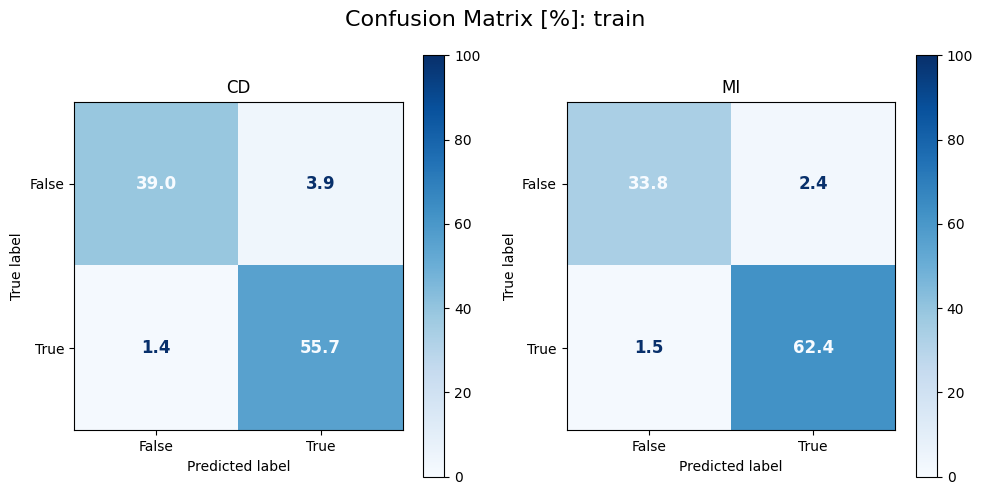

Hamming loss: 0.05
Accuracy- Strict: 0.93
Jaccard score- samples: 0.95
Jaccard score- macro: 0.93
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.94      0.98      0.95      4402
          MI       0.96      0.98      0.97      4919

   micro avg       0.95      0.98      0.96      9321
   macro avg       0.95      0.98      0.96      9321
weighted avg       0.95      0.98      0.96      9321
 samples avg       0.96      0.98      0.96      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
cd_mi_HR_scores_train = multi_labels_evaluation(y_train_for_CD_MI_encoded, y_train_pred_encoded, ['CD','MI'], "train")
# proba_graph(y_train_for_CD_MI_encoded, y_train_pred_encoded, ['CD','MI'], "train")

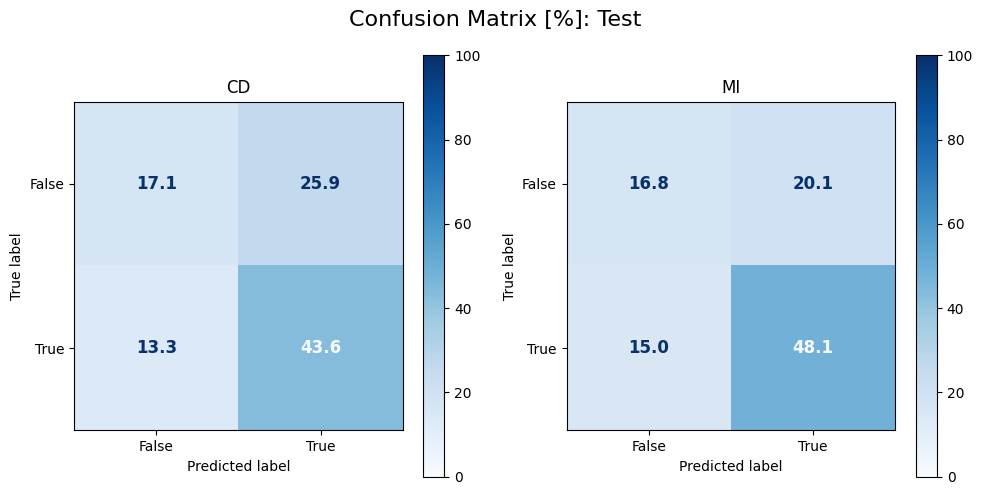

Hamming loss: 0.37
Accuracy- Strict: 0.41
Jaccard score- samples: 0.62
Jaccard score- macro: 0.55
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.63      0.77      0.69       496
          MI       0.71      0.76      0.73       550

   micro avg       0.67      0.76      0.71      1046
   macro avg       0.67      0.76      0.71      1046
weighted avg       0.67      0.76      0.71      1046
 samples avg       0.68      0.77      0.69      1046



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
cd_mi_HR_scores_test = multi_labels_evaluation(y_test_for_CD_MI_encoded, y_test_pred_encoded, ['CD','MI'], "Test")
# proba_graph(y_test_for_CD_MI_encoded, y_test_pred_encoded, ['CD','MI'], "train")

In [ ]:
scores_dict_2L['baseline-100Hz']= {"train": cd_mi_HR_scores_train, "test": cd_mi_HR_scores_test}

## 2 Labels (CD, MI), 500Hz

In [ ]:
## add relvant code line

#### Preprocessing & train

In [ ]:
## add relvant code line

#### Evaluation

In [ ]:
y_train_for_CD_MI_encoded = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/y_train_for_CD_MI_encoded.npy')
y_test_for_CD_MI_encoded = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/y_test_for_CD_MI_encoded.npy')
y_train_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-14, Multi-Label CNN, 2 Labels (CD, MI), 500Hz/ECG-4096_mod-CNNml_lab-2_TimeStamp_2024-01-14_00-39_+20epochs_y_train_pred.npy')
y_train_pred_encoded = (y_train_pred>thr).astype(int)
y_test_pred = np.load('/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-14, Multi-Label CNN, 2 Labels (CD, MI), 500Hz/ECG-4096_mod-CNNml_lab-2_TimeStamp_2024-01-14_00-39_+20epochs_y_test_pred.npy')
y_test_pred_encoded = (y_test_pred>thr).astype(int)


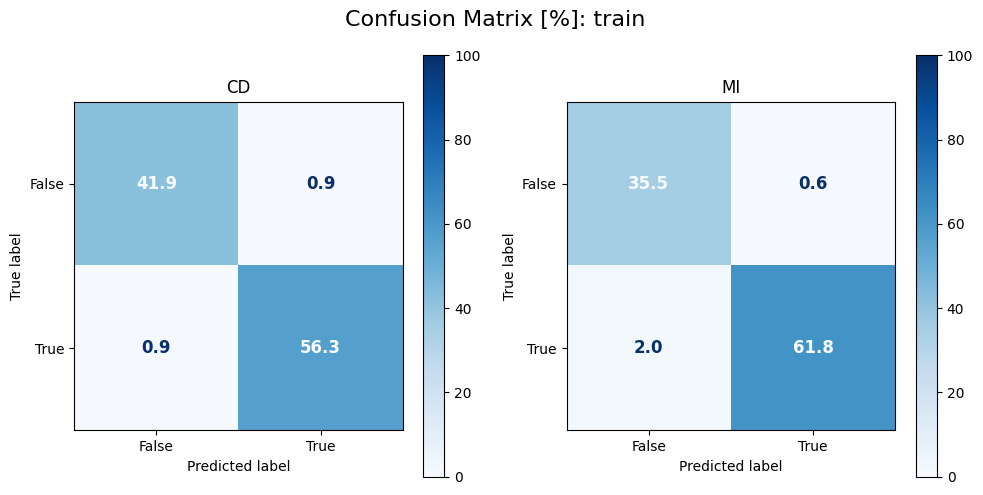

Hamming loss: 0.02
Accuracy- Strict: 0.96
Jaccard score- samples: 0.97
Jaccard score- macro: 0.96
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.98      0.99      0.98      4402
          MI       0.99      0.97      0.98      4919

   micro avg       0.99      0.98      0.98      9321
   macro avg       0.99      0.98      0.98      9321
weighted avg       0.99      0.98      0.98      9321
 samples avg       0.98      0.98      0.98      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
cd_mi_HR_scores_train = multi_labels_evaluation(y_train_for_CD_MI_encoded, y_train_pred_encoded, ['CD','MI'], "train")
# proba_graph(y_train_for_CD_MI_encoded, y_train_pred_encoded, ['CD','MI'], "train")

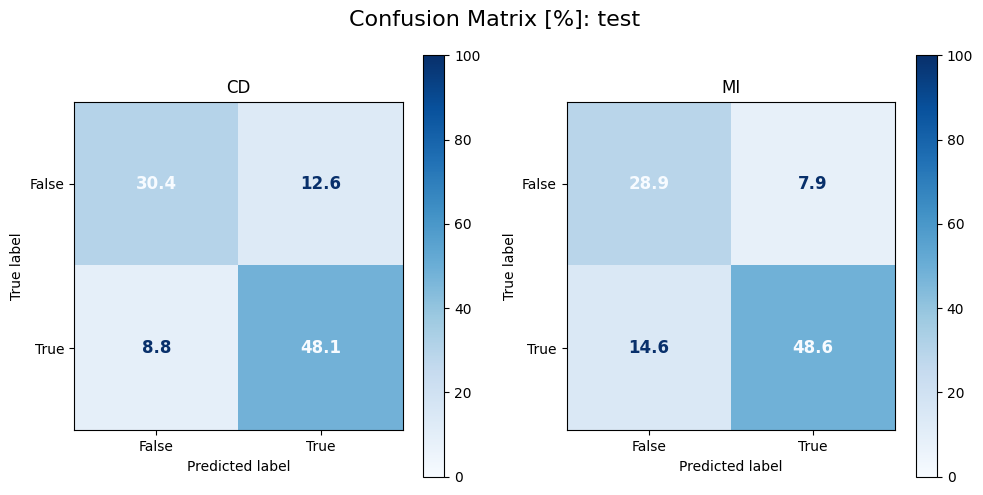

Hamming loss: 0.22
Accuracy- Strict: 0.65
Jaccard score- samples: 0.77
Jaccard score- macro: 0.69
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.79      0.84      0.82       496
          MI       0.86      0.77      0.81       550

   micro avg       0.82      0.80      0.81      1046
   macro avg       0.83      0.81      0.81      1046
weighted avg       0.83      0.80      0.81      1046
 samples avg       0.82      0.83      0.80      1046



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
cd_mi_HR_scores_test = multi_labels_evaluation(y_test_for_CD_MI_encoded, y_test_pred_encoded, ['CD','MI'], "test")
# proba_graph(y_test_for_CD_MI_encoded, y_test_pred_encoded, ['CD','MI'], "train")

In [ ]:
scores_dict_2L['baseline-500Hz']= {"train": cd_mi_HR_scores_train, "test": cd_mi_HR_scores_test}


## 2 Labels (CD, MI), 500Hz + noise & moving average


In [ ]:
## add relvant code line

#### Preprocessing & train

In [ ]:
## add relvant code line

#### Evaluation

__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_winSize-10_History.cs


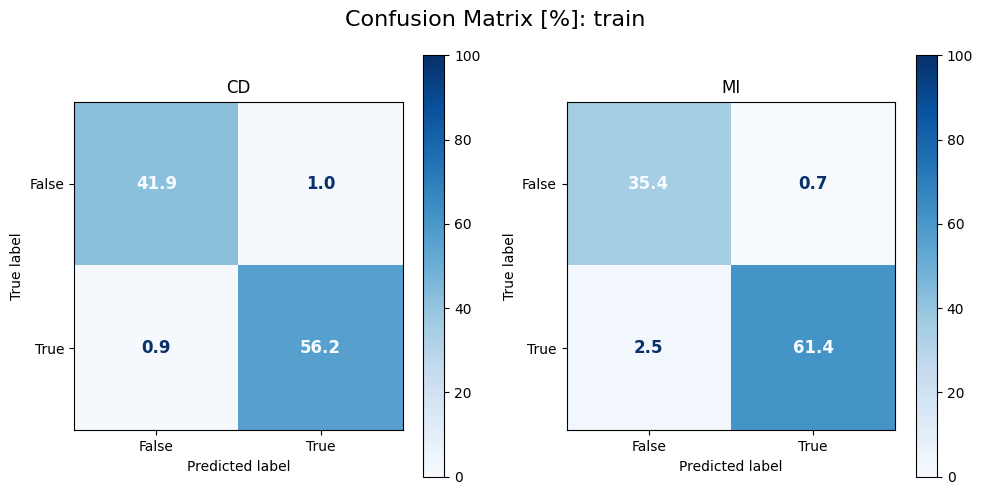

Hamming loss: 0.03
Accuracy- Strict: 0.96
Jaccard score- samples: 0.97
Jaccard score- macro: 0.96
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.98      0.98      0.98      4402
          MI       0.99      0.96      0.98      4919

   micro avg       0.99      0.97      0.98      9321
   macro avg       0.99      0.97      0.98      9321
weighted avg       0.99      0.97      0.98      9321
 samples avg       0.99      0.98      0.98      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


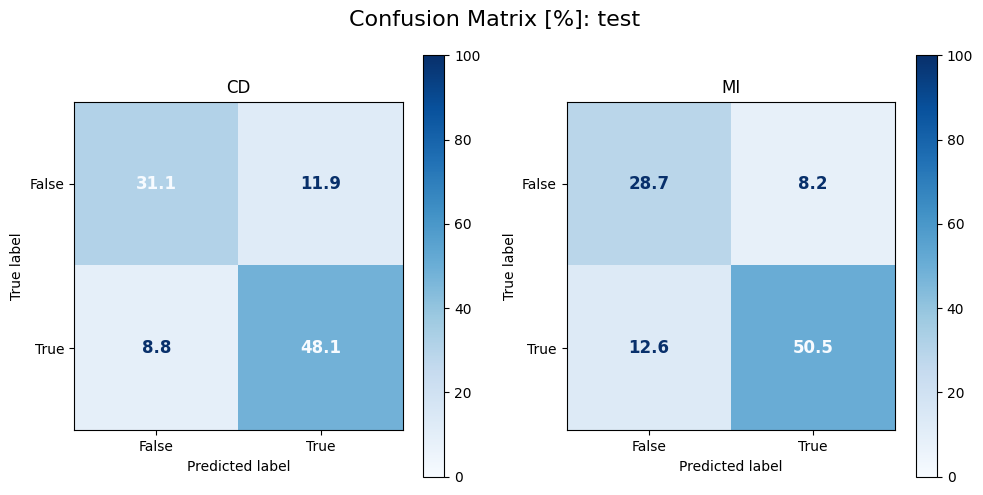

Hamming loss: 0.21
Accuracy- Strict: 0.66
Jaccard score- samples: 0.78
Jaccard score- macro: 0.70
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.80      0.84      0.82       496
          MI       0.86      0.80      0.83       550

   micro avg       0.83      0.82      0.83      1046
   macro avg       0.83      0.82      0.83      1046
weighted avg       0.83      0.82      0.83      1046
 samples avg       0.84      0.85      0.82      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_winSize-20_History.cs


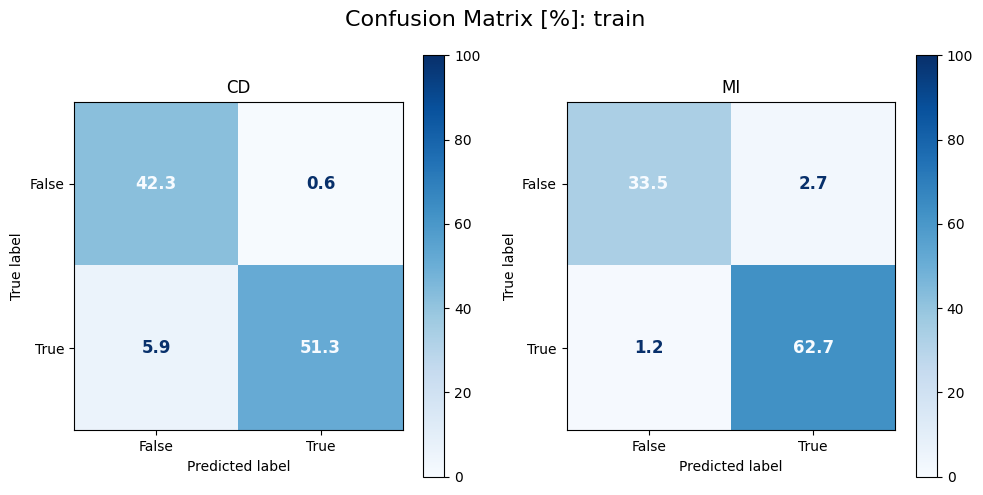

Hamming loss: 0.05
Accuracy- Strict: 0.91
Jaccard score- samples: 0.94
Jaccard score- macro: 0.92
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.99      0.90      0.94      4402
          MI       0.96      0.98      0.97      4919

   micro avg       0.97      0.94      0.96      9321
   macro avg       0.97      0.94      0.96      9321
weighted avg       0.97      0.94      0.96      9321
 samples avg       0.96      0.95      0.95      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


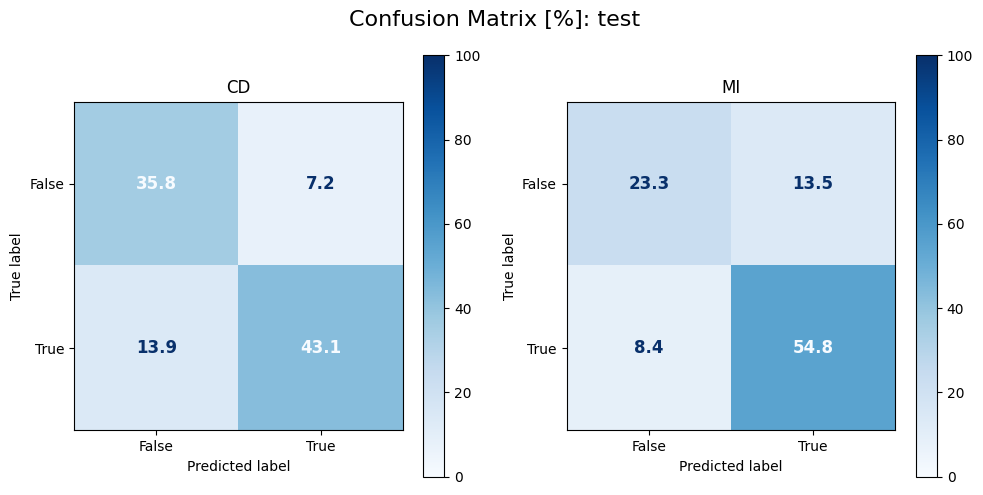

Hamming loss: 0.22
Accuracy- Strict: 0.66
Jaccard score- samples: 0.77
Jaccard score- macro: 0.69
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.86      0.76      0.80       496
          MI       0.80      0.87      0.83       550

   micro avg       0.82      0.81      0.82      1046
   macro avg       0.83      0.81      0.82      1046
weighted avg       0.83      0.81      0.82      1046
 samples avg       0.82      0.83      0.81      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_winSize-50


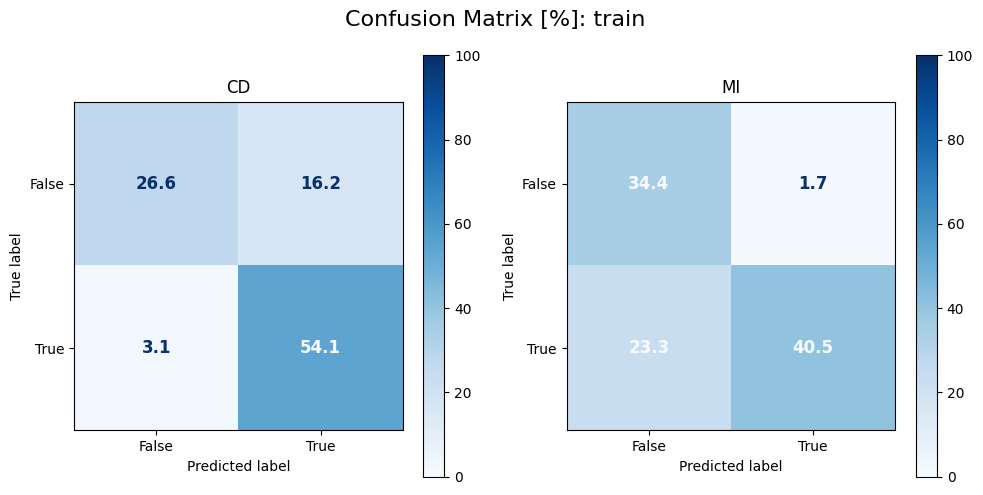

Hamming loss: 0.22
Accuracy- Strict: 0.68
Jaccard score- samples: 0.76
Jaccard score- macro: 0.68
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.77      0.95      0.85      4402
          MI       0.96      0.63      0.76      4919

   micro avg       0.84      0.78      0.81      9321
   macro avg       0.86      0.79      0.81      9321
weighted avg       0.87      0.78      0.80      9321
 samples avg       0.82      0.79      0.79      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


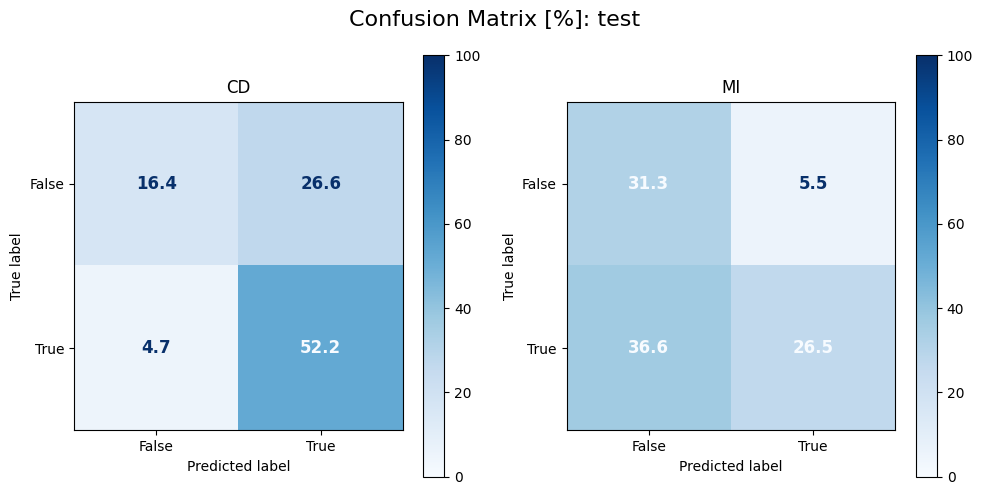

Hamming loss: 0.37
Accuracy- Strict: 0.50
Jaccard score- samples: 0.62
Jaccard score- macro: 0.51
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.66      0.92      0.77       496
          MI       0.83      0.42      0.56       550

   micro avg       0.71      0.66      0.68      1046
   macro avg       0.75      0.67      0.66      1046
weighted avg       0.75      0.66      0.66      1046
 samples avg       0.69      0.66      0.66      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.01


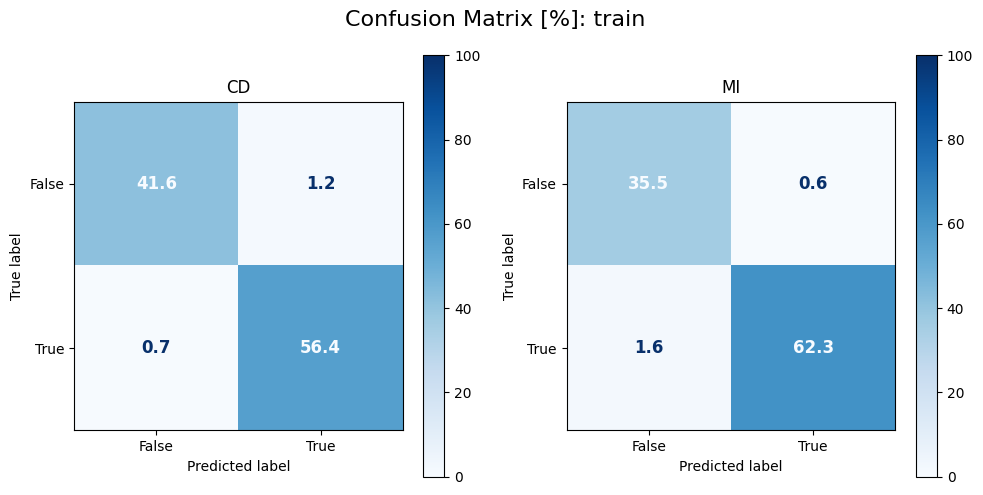

Hamming loss: 0.02
Accuracy- Strict: 0.97
Jaccard score- samples: 0.98
Jaccard score- macro: 0.97
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.98      0.99      0.98      4402
          MI       0.99      0.98      0.98      4919

   micro avg       0.98      0.98      0.98      9321
   macro avg       0.98      0.98      0.98      9321
weighted avg       0.98      0.98      0.98      9321
 samples avg       0.99      0.99      0.98      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


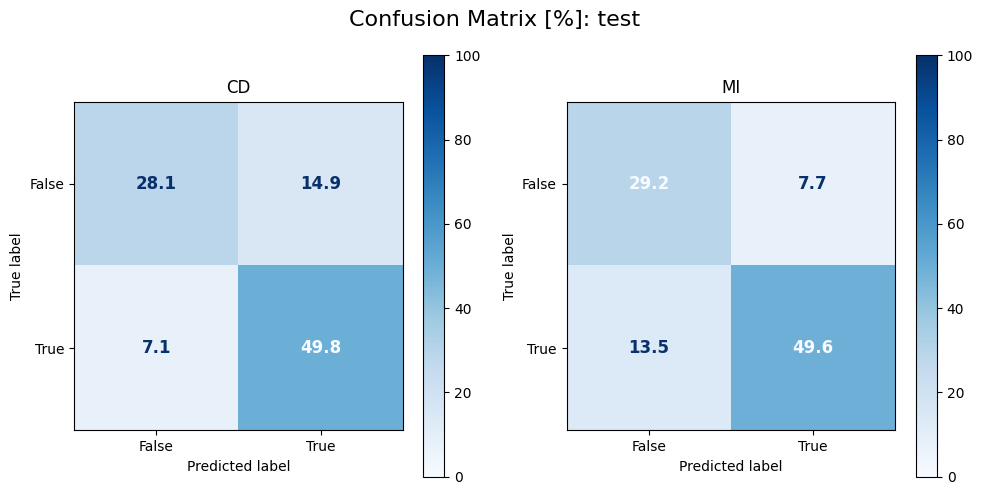

Hamming loss: 0.22
Accuracy- Strict: 0.64
Jaccard score- samples: 0.77
Jaccard score- macro: 0.70
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.77      0.88      0.82       496
          MI       0.87      0.79      0.82       550

   micro avg       0.81      0.83      0.82      1046
   macro avg       0.82      0.83      0.82      1046
weighted avg       0.82      0.83      0.82      1046
 samples avg       0.83      0.85      0.82      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.03_History.cs


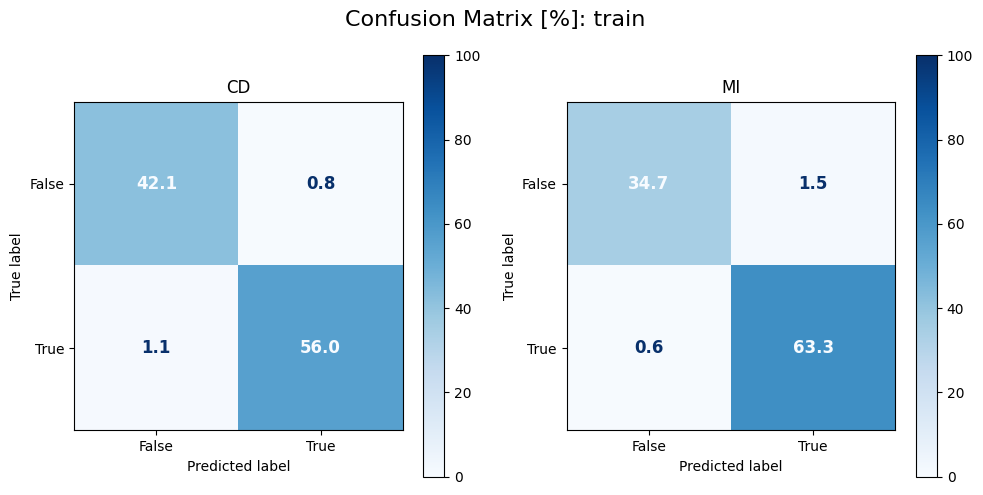

Hamming loss: 0.02
Accuracy- Strict: 0.96
Jaccard score- samples: 0.98
Jaccard score- macro: 0.97
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.99      0.98      0.98      4402
          MI       0.98      0.99      0.98      4919

   micro avg       0.98      0.99      0.98      9321
   macro avg       0.98      0.99      0.98      9321
weighted avg       0.98      0.99      0.98      9321
 samples avg       0.99      0.99      0.99      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


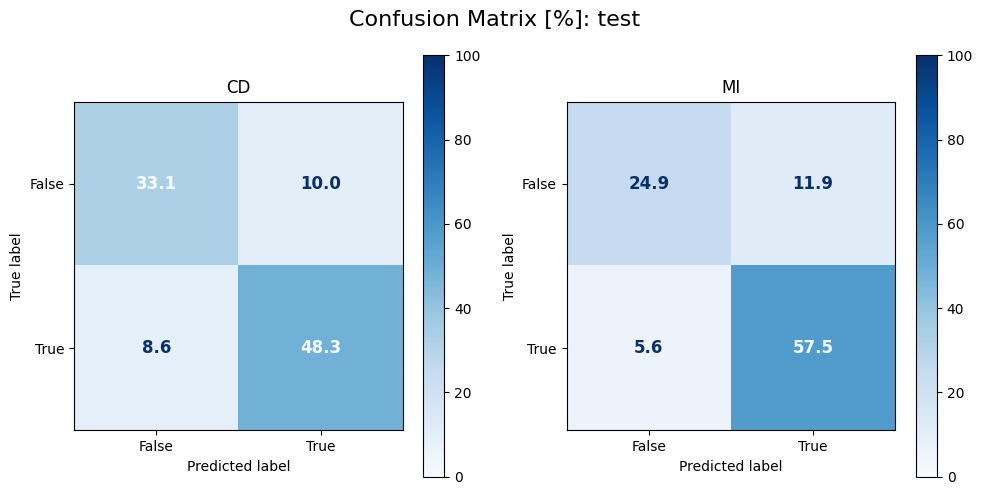

Hamming loss: 0.18
Accuracy- Strict: 0.69
Jaccard score- samples: 0.82
Jaccard score- macro: 0.74
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.83      0.85      0.84       496
          MI       0.83      0.91      0.87       550

   micro avg       0.83      0.88      0.85      1046
   macro avg       0.83      0.88      0.85      1046
weighted avg       0.83      0.88      0.85      1046
 samples avg       0.86      0.90      0.86      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


__________________________________________________________________________________________________
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.05_y_test_pred.np


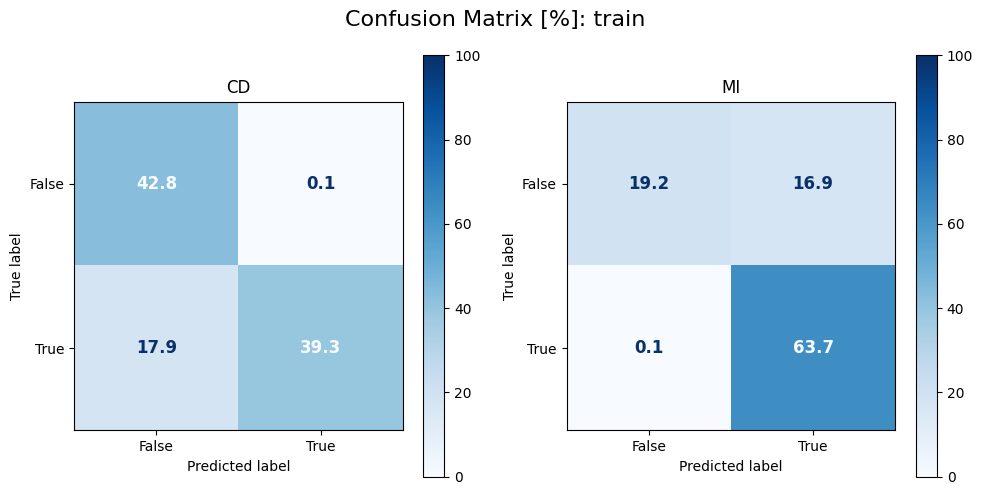

Hamming loss: 0.17
Accuracy- Strict: 0.73
Jaccard score- samples: 0.82
Jaccard score- macro: 0.74
-------------------------------------------
              precision    recall  f1-score   support

          CD       1.00      0.69      0.81      4402
          MI       0.79      1.00      0.88      4919

   micro avg       0.86      0.85      0.85      9321
   macro avg       0.89      0.84      0.85      9321
weighted avg       0.89      0.85      0.85      9321
 samples avg       0.86      0.86      0.85      9321



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


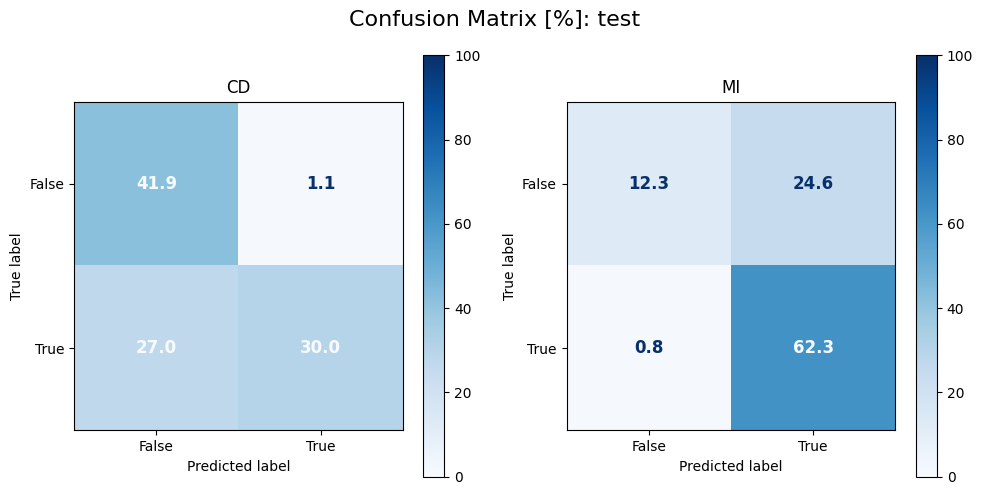

Hamming loss: 0.27
Accuracy- Strict: 0.61
Jaccard score- samples: 0.73
Jaccard score- macro: 0.61
-------------------------------------------
              precision    recall  f1-score   support

          CD       0.96      0.53      0.68       496
          MI       0.72      0.99      0.83       550

   micro avg       0.78      0.77      0.78      1046
   macro avg       0.84      0.76      0.76      1046
weighted avg       0.83      0.77      0.76      1046
 samples avg       0.79      0.78      0.77      1046

__________________________________________________________________________________________________


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
folder_path = '/content/drive/MyDrive/ECG - Naya, Final Project/2024-01-14, Multi-Label CNN, 2 Labels (CD, MI), 500Hz - Smooth and Noise'
for folder_name, subfolders, files in os.walk(folder_path):
  y_train_path =[]
  y_test_path = []
  for file_name in files:
    if "y_train" in file_name:
      y_train_path = os.path.join(folder_name, file_name)
    elif "y_test" in file_name:
      y_test_path = os.path.join(folder_name, file_name)
  if not y_train_path or not y_test_path:
    pass
    # print(f"No saved files for folder: {folder_name}")
  else:
    index = file_name.find("_y_train")
    current_model_name = file_name[:index]
    y_train_pred = np.load(y_train_path)
    y_train_pred_encoded = (y_train_pred>thr).astype(int)
    y_test_pred = np.load(y_test_path)
    y_test_pred_encoded = (y_test_pred>thr).astype(int)
    print('__________________________________________________________________________________________________')
    print(current_model_name)
    train_score = multi_labels_evaluation(y_train_for_CD_MI_encoded, y_train_pred_encoded, ['CD','MI'], "train")
    test_score = multi_labels_evaluation(y_test_for_CD_MI_encoded, y_test_pred_encoded, ['CD','MI'], "test")
    print('__________________________________________________________________________________________________')
    scores_dict_2L[current_model_name]= {'train': train_score, 'test': test_score}




## Summary results (2 labels):

In [ ]:
print_dict_results(scores_dict_2L)

<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))
<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))
<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))
<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append(pd.Series(model_row, name=model))
<ipython-input-32-68b9031c6e96>:15: FutureWarning: The frame.append method is deprecated and will be removed from pandas

,train_Hamming Loss,test_Hamming Loss,train_Accuracy- S,test_Accuracy- S,train_Jaccard score- samples,test_Jaccard score- samples,train_Jaccard score- macro,test_Jaccard score- macro
baseline-100Hz,0.05,0.37,0.93,0.41,0.95,0.62,0.93,0.55
baseline-500Hz,0.02,0.22,0.96,0.65,0.97,0.77,0.96,0.69
ECG-4096_mod-CNNml_lab-2_winSize-10_History.cs,0.03,0.21,0.96,0.66,0.97,0.78,0.96,0.70
ECG-4096_mod-CNNml_lab-2_winSize-20_History.cs,0.05,0.22,0.91,0.66,0.94,0.77,0.92,0.69
ECG-4096_mod-CNNml_lab-2_winSize-50,0.22,0.37,0.68,0.50,0.76,0.62,0.68,0.51
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.01,0.02,0.22,0.97,0.64,0.98,0.77,0.97,0.70
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.03_History.cs,0.02,0.18,0.96,0.69,0.98,0.82,0.97,0.74
ECG-4096_mod-CNNml_lab-2_noiseSigma-0.05_y_test_pred.np,0.17,0.27,0.73,0.61,0.82,0.73,0.74,0.61


# Multi-Label (6) with HR data:

#To insert:
* Downsampling function
* signals FFT plot
* history graph of the model

# Obsolete

#### Remove Not Classified and Missing Calssification Data

In [ ]:
# X_train, y_train = remove_data_by_labels(X_train, y_train, ['Not Classified'])
# X_test, y_test = remove_data_by_labels(X_train, y_train, ['Not Classified'])

In [ ]:
# y_train.value_counts()

NORM              8157
MI                2276
STTC              2158
CD                1524
MI CD             1164
HYP STTC           708
MI STTC            538
HYP                479
NORM CD            362
MI HYP STTC        320
HYP CD             273
STTC CD            249
CD STTC            184
MI HYP             166
CD HYP STTC        116
MI HYP CD          112
MI STTC CD         105
MI CD STTC          97
MI HYP CD STTC      92
HYP STTC CD         56
MI HYP STTC CD      43
NORM STTC           24
STTC HYP CD         14
NORM STTC CD         5
MI STTC HYP CD       5
NORM HYP             2
MI NORM HYP CD       1
Name: count, dtype: int64

## Pipelines

#### Pipeline as "Pipline" - Need Code Rreview

In [ ]:
class PaddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, maxlen=1024):
        self.maxlen = maxlen

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return pad_sequences(X, maxlen=self.maxlen, padding='post', truncating='post')

class MultiLabelBinarizerTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.encoder = MultiLabelBinarizer()
        self.encoder.fit(X)
        return self

    def transform(self, X):
        return self.encoder.transform(X)

class KerasModelTrainer(BaseEstimator):
    def __init__(self, model_func, epochs=50, batch_size=64, learning_rate=0.001, validation_split=0.1):
        self.model_func = model_func
        self.epochs = epochs
        self.batch_size = batch_size
        self.learning_rate = learning_rate
        self.validation_split = validation_split
        self.model_ = None

    def fit(self, X, y):
        self.model_ = self.model_func(len(set(y)))
        optimizer = Adam(learning_rate=self.learning_rate)
        self.model_.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])
        self.model_.fit(X, y, epochs=self.epochs, batch_size=self.batch_size, verbose=1, validation_split=self.validation_split)
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def save_model(self, path):
        self.model_.save(path)
        return self

# Usage
# Define a function get_model() that returns your Keras model

pipeline = Pipeline([
    ('pad', PaddingTransformer(maxlen=1024)),
    ('binarize', MultiLabelBinarizerTransformer()),
    ('train', KerasModelTrainer(model_func=get_model, epochs=50, batch_size=64, learning_rate=0.001, validation_split=0.1))
])

# Fit the pipeline
pipeline.fit(X_train, y_train)

# Save the model
pipeline.named_steps['train'].save_model('model.h5')

##### Predict

In [ ]:
# Predict
# predictions = pipeline.predict(X_test)

#### Padding

In [ ]:
def padding(X):
    return pad_sequences(X, maxlen=1024, padding='post', truncating='post')

signals_pipeline = Pipeline([
    ('pad_sequences', FunctionTransformer(func= padding))
])
signals_pipeline

Pipeline(steps=[('pad_sequences',
                 FunctionTransformer(func=<function padding at 0x0000011FD114A8E0>))])

In [ ]:
padd_sig = signals_pipeline.transform(X_train)
padd_sig.shape

(19601, 1024, 12)

In [ ]:
ecg_model_ml